In [1]:
import sys

print(sys.version)
print(sys.executable)
    

3.13.4 (tags/v3.13.4:8a526ec, Jun  3 2025, 17:46:04) [MSC v.1943 64 bit (AMD64)]
c:\Machine Learning\GP\.venv\Scripts\python.exe


In [2]:
%pip install pandas numpy matplotlib seaborn scikit-learn ucimlrepo

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
from ucimlrepo import fetch_ucirepo
from IPython.display import display

# Load the UCI credit card dataset
credit = fetch_ucirepo(id=350)

# X: information used to make predictions
# y: the actual outcome we want to predict
X = credit.data.features.copy()
y = credit.data.targets.iloc[:, 0].copy()

print("Feature table shape:", X.shape)
print("Target column:", y.name)

display(X.head())

print("\nTarget counts:")
print(y.value_counts(dropna=False).sort_index())

print("\nTarget percentages (%):")
print((y.value_counts(normalize=True) * 100).round(2).sort_index())

print("\nMissing feature values:", X.isna().sum().sum())
print("Missing target values:", y.isna().sum())

Feature table shape: (30000, 23)
Target column: Y


,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,...,X14,X15,X16,X17,X18,X19,X20,X21,X22,X23
0,20000,2,2,1,24,2,2,-1,-1,-2,...,689,0,0,0,0,689,0,0,0,0
1,120000,2,2,2,26,-1,2,0,0,0,...,2682,3272,3455,3261,0,1000,1000,1000,0,2000
2,90000,2,2,2,34,0,0,0,0,0,...,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000
3,50000,2,2,1,37,0,0,0,0,0,...,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000
4,50000,1,2,1,57,-1,0,-1,0,0,...,35835,20940,19146,19131,2000,36681,10000,9000,689,679



Target counts:
Y
0    23364
1     6636
Name: count, dtype: int64

Target percentages (%):
Y
0    77.88
1    22.12
Name: proportion, dtype: float64

Missing feature values: 0
Missing target values: 0


In [4]:
# Create a dictionary mapping the current column names to descriptive names
column_names = {
    "X1": "LIMIT_BAL",       # Credit limit
    "X2": "SEX",             # Sex category code
    "X3": "EDUCATION",       # Education level code
    "X4": "MARRIAGE",        # Marital status code
    "X5": "AGE",             # Age in years

    # Repayment status for the six months from September to April 2005
    "X6": "PAY_0",
    "X7": "PAY_2",
    "X8": "PAY_3",
    "X9": "PAY_4",
    "X10": "PAY_5",
    "X11": "PAY_6",

    # Monthly bill amounts from September to April 2005
    "X12": "BILL_AMT1",
    "X13": "BILL_AMT2",
    "X14": "BILL_AMT3",
    "X15": "BILL_AMT4",
    "X16": "BILL_AMT5",
    "X17": "BILL_AMT6",

    # Monthly payment amounts from September to April 2005
    "X18": "PAY_AMT1",
    "X19": "PAY_AMT2",
    "X20": "PAY_AMT3",
    "X21": "PAY_AMT4",
    "X22": "PAY_AMT5",
    "X23": "PAY_AMT6"
}

# Rename the feature columns using the dictionary
# Assign the result back to X to retain the updated column names
X = X.rename(columns=column_names)

# Give the target variable a more descriptive name
y = y.rename("DEFAULT_NEXT_MONTH")

# Display the first five rows to check the updated column names
display(X.head())

,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6
0,20000,2,2,1,24,2,2,-1,-1,-2,...,689,0,0,0,0,689,0,0,0,0
1,120000,2,2,2,26,-1,2,0,0,0,...,2682,3272,3455,3261,0,1000,1000,1000,0,2000
2,90000,2,2,2,34,0,0,0,0,0,...,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000
3,50000,2,2,1,37,0,0,0,0,0,...,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000
4,50000,1,2,1,57,-1,0,-1,0,0,...,35835,20940,19146,19131,2000,36681,10000,9000,689,679


In [5]:
# Import the function for splitting data into training and test sets
from sklearn.model_selection import train_test_split

# Split X and y together to keep each customer's features and label aligned
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,    # Reserve 20% for testing and 80% for training
    random_state=42,   # Use a fixed random seed to make the split reproducible
    stratify=y        # Preserve approximately the same class proportions in both sets
)

# Check the dimensions of the training and test sets
print("Training features:", X_train.shape)
print("Test features:", X_test.shape)
print("Training targets:", y_train.shape)
print("Test targets:", y_test.shape)

Training features: (24000, 23)
Test features: (6000, 23)
Training targets: (24000,)
Test targets: (6000,)


In [6]:
import pandas as pd

# Create a data quality summary with one row per feature
quality_summary = pd.DataFrame({
    # Show the storage type; for example, int64 represents integers
    "Data type": X_train.dtypes.astype(str),

    # Count the missing values in each column
    "Missing values": X_train.isna().sum(),

    # Count the distinct non-missing values in each column
    "Unique values": X_train.nunique()
})

display(quality_summary)


# Inspect the category codes and their frequencies for selected features
# PAY_0 represents the most recent month's repayment status
for column in ["SEX", "EDUCATION", "MARRIAGE", "PAY_0"]:
    print(f"\nCategory counts for {column}:")
    print(X_train[column].value_counts(dropna=False).sort_index())


# Examine summary statistics for credit limit and age
# describe() returns the count, mean, standard deviation, minimum,
# quartiles and maximum
# .T transposes the table so that each variable appears in a separate row
display(X_train[["LIMIT_BAL", "AGE"]].describe().T)


# Create a temporary table containing the features and their actual labels
# pandas aligns the features and labels using their original row indices
train_check = X_train.copy()
train_check[y_train.name] = y_train

# Count additional records identical to an earlier row across all columns
# By default, the first occurrence is not marked as a duplicate;
# subsequent occurrences are marked as duplicates
print(
    "\nRepeated rows (features + target):",
    train_check.duplicated().sum()
)

,Data type,Missing values,Unique values
LIMIT_BAL,int64,0,80
SEX,int64,0,2
EDUCATION,int64,0,7
MARRIAGE,int64,0,4
AGE,int64,0,55
PAY_0,int64,0,11
PAY_2,int64,0,11
PAY_3,int64,0,11
PAY_4,int64,0,11
PAY_5,int64,0,10



Category counts for SEX:
SEX
1     9486
2    14514
Name: count, dtype: int64

Category counts for EDUCATION:
EDUCATION
0       12
1     8455
2    11256
3     3903
4       97
5      235
6       42
Name: count, dtype: int64

Category counts for MARRIAGE:
MARRIAGE
0       47
1    10892
2    12806
3      255
Name: count, dtype: int64

Category counts for PAY_0:
PAY_0
-2     2198
-1     4527
 0    11781
 1     3000
 2     2138
 3      245
 4       58
 5       18
 6       10
 7        9
 8       16
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
LIMIT_BAL,24000.0,167364.666667,129511.313151,10000.0,50000.0,140000.0,240000.0,1000000.0
AGE,24000.0,35.432625,9.195256,21.0,28.0,34.0,41.0,75.0



Repeated rows (features + target): 26


In [7]:
# 单独显示最近一个月还款状态的完整类别统计
display(X_train["PAY_0"].value_counts(dropna=False).sort_index())

PAY_0
-2     2198
-1     4527
 0    11781
 1     3000
 2     2138
 3      245
 4       58
 5       18
 6       10
 7        9
 8       16
Name: count, dtype: int64

Inspection of the training set identified 11 distinct codes in PAY_0, covering all 24,000 training records. The distribution was uneven, with code 0 occurring most frequently and higher delay categories appearing relatively rarely. The UCI documentation defines -1 as timely payment and positive codes as months of payment delay, but does not explicitly explain codes -2 and 0. These codes should therefore be retained pending clarification, rather than automatically treated as missing or invalid values.

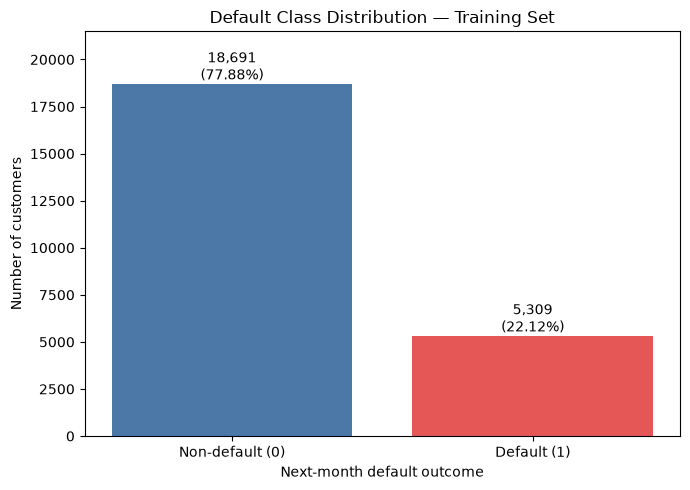

In [8]:
import matplotlib.pyplot as plt
from pathlib import Path

# Count the records in each target class in the training set
# reindex fixes the order: 0 = non-default, 1 = default
counts = y_train.value_counts().reindex([0, 1], fill_value=0)

# Divide each class count by the total and convert it to a percentage
percentages = counts / counts.sum() * 100

# Create the figure and plotting area
fig, ax = plt.subplots(figsize=(7, 5))

# Draw two bars with heights representing the number of customers
bars = ax.bar(
    ["Non-default (0)", "Default (1)"],
    counts.to_numpy(),
    color=["#4C78A8", "#E45756"]
)

# zip pairs each bar with its corresponding count and percentage
# Add the count and percentage above each bar
for bar, count, percentage in zip(bars, counts, percentages):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{count:,}\n({percentage:.2f}%)",
        ha="center",
        va="bottom"
    )

# Set the chart title and axis labels
ax.set_title("Default Class Distribution — Training Set")
ax.set_xlabel("Next-month default outcome")
ax.set_ylabel("Number of customers")

# Leave space above the bars to prevent the annotations from being clipped
ax.set_ylim(0, counts.max() * 1.15)

# Automatically adjust the layout
fig.tight_layout()

# Create the figures folder if needed and save a high-resolution image
# The saved image can be inserted into the report
Path("figures").mkdir(exist_ok=True)
fig.savefig(
    "figures/01_target_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

# Display the chart in the notebook
plt.show()


The training set contains 18,691 non-default customers (77.88%) and 5,309 default customers (22.12%), indicating class imbalance. Accuracy alone may therefore be misleading. Model evaluation will also consider precision, recall and F1-score for the default class, alongside ROC-AUC.

Age distribution - Which age ranges contain most customers? Are there fewer customers at the youngest and oldest ages?

Credit limit distribution - Are most customers concentrated in the lower credit limit range? Do a small number of customers with high credit limits create a long right-hand tail?


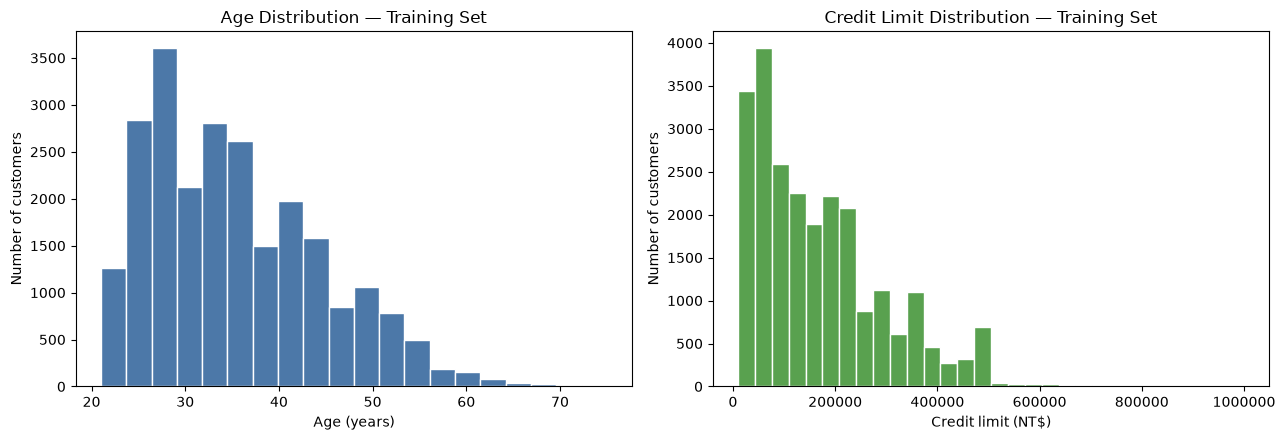

In [9]:
import matplotlib.pyplot as plt
from pathlib import Path

# Create a figure containing two side-by-side plotting areas
# axes[0] is the left plot, and axes[1] is the right plot
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))


# Left plot: age histogram
# bins=20 divides the age range into 20 intervals
# Each bar's height represents the number of customers in that interval
axes[0].hist(
    X_train["AGE"],
    bins=20,
    color="#4C78A8",
    edgecolor="white"
)

axes[0].set_title("Age Distribution — Training Set")
axes[0].set_xlabel("Age (years)")
axes[0].set_ylabel("Number of customers")


# Right plot: credit limit histogram
# bins=30 divides the credit limit range into 30 intervals
axes[1].hist(
    X_train["LIMIT_BAL"],
    bins=30,
    color="#59A14F",
    edgecolor="white"
)

axes[1].set_title("Credit Limit Distribution — Training Set")
axes[1].set_xlabel("Credit limit (NT$)")
axes[1].set_ylabel("Number of customers")

# Display x-axis values in plain notation rather than scientific notation
axes[1].ticklabel_format(axis="x", style="plain")

# Automatically adjust the spacing between the plots
fig.tight_layout()

# Create the figures folder if needed and save a high-resolution image
# The saved image can be used in the report
Path("figures").mkdir(exist_ok=True)
fig.savefig(
    "figures/02_age_credit_limit_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

# Display the figure in the notebook
plt.show()

Most customers are in their twenties to forties. Credit limits show a clearly right-skewed distribution, with relatively few customers having very high limits. These plots describe customer characteristics; further analysis is needed to examine their relationship with default.


1. **The age distribution is slightly right-skewed.** Most customers are in their twenties to forties, with fewer customers in the older age groups. The mean age is approximately **35.43 years**, and the median is **34 years**.

2. **The credit limit distribution is clearly right-skewed.** Lower credit limits are more common, while a small number of customers with high limits form a long right tail. The median credit limit is **NT$140,000**, and the mean is approximately **NT$167,365**.

3. **A high credit limit alone does not justify removing a record.** Decisions about these observations should consider their business meaning. For Logistic Regression, we will standardise numerical features to address differences in scale, learning the standardisation parameters from the training data only.


# What is the relationship between repayment status in the most recent month and the default rate in the following month?

,customers,defaults,default_rate_pct
PAY_0,,,
-2,2198,279,12.69
-1,4527,753,16.63
0,11781,1508,12.80
1,3000,1031,34.37
2,2138,1483,69.36
3,245,188,76.73
4,58,38,65.52
5,18,8,44.44
6,10,6,60.00


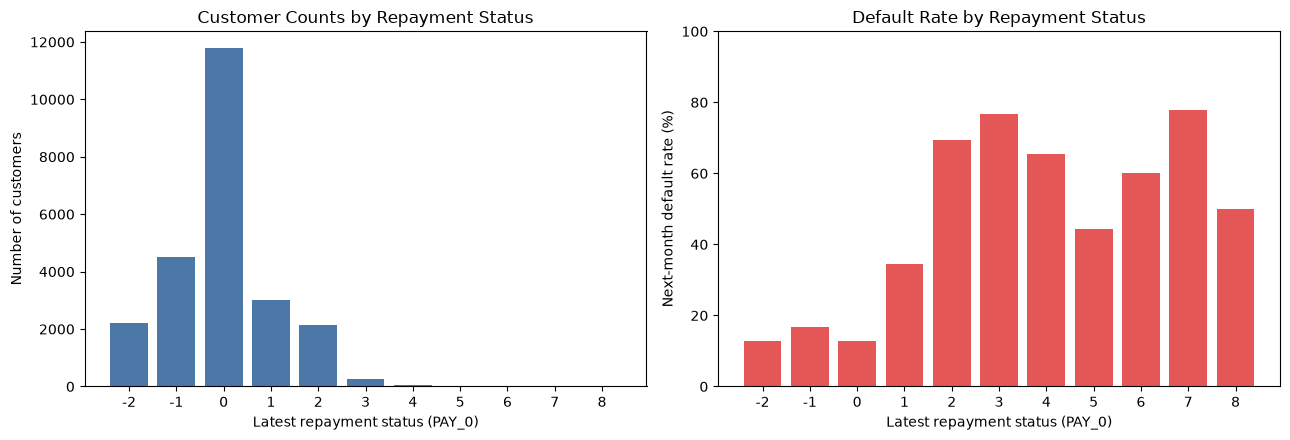

In [10]:
import matplotlib.pyplot as plt
from pathlib import Path

# Create a copy of the training features for exploratory analysis
# Add the corresponding target labels to examine their relationships
eda_train = X_train.copy()
eda_train["DEFAULT_NEXT_MONTH"] = y_train


# Group customers by their most recent repayment status (PAY_0)
# Calculate the customer count, default count and default proportion
pay_summary = (
    eda_train.groupby("PAY_0")["DEFAULT_NEXT_MONTH"]
    .agg(
        customers="size",       # Total number of customers in each group
        defaults="sum",         # Number of defaults, since default = 1
        default_rate="mean"     # Mean of binary labels = default proportion
    )
    .sort_index()               # Sort groups by repayment status code
)

# Convert default proportions into percentages
pay_summary["default_rate_pct"] = pay_summary["default_rate"] * 100

# Display the summary table, rounded to two decimal places
display(
    pay_summary[
        ["customers", "defaults", "default_rate_pct"]
    ].round(2)
)


# Create two plotting areas side by side
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Convert status codes to strings so they appear as distinct categories
labels = pay_summary.index.astype(str)

# Left chart: number of customers in each repayment status category
axes[0].bar(labels, pay_summary["customers"], color="#4C78A8")
axes[0].set_title("Customer Counts by Repayment Status")
axes[0].set_xlabel("Latest repayment status (PAY_0)")
axes[0].set_ylabel("Number of customers")

# Right chart: next-month default percentage within each category
axes[1].bar(labels, pay_summary["default_rate_pct"], color="#E45756")
axes[1].set_title("Default Rate by Repayment Status")
axes[1].set_xlabel("Latest repayment status (PAY_0)")
axes[1].set_ylabel("Next-month default rate (%)")

# Use a percentage scale from 0 to 100
axes[1].set_ylim(0, 100)

# Adjust spacing to prevent titles and labels from overlapping
fig.tight_layout()

# Create the figures folder if it does not already exist
Path("figures").mkdir(exist_ok=True)

# Save a high-resolution image for the report
fig.savefig(
    "figures/03_repayment_status_default_rate.png",
    dpi=300,
    bbox_inches="tight"
)

# Display the charts in the notebook
plt.show()

The key part of the code is:

```python
default_rate="mean"
```

The target variable contains only `0` (non-default) and `1` (default), so its mean equals the proportion of customers who default within each group.

For example, if a group contains **10 customers**, of whom **4 default**:

**Default rate = 4 ÷ 10 = 0.4 = 40%**

Default rates vary substantially across repayment-status groups, suggesting that recent repayment behaviour may be useful for prediction. However, groups with very few customers have less reliable rate estimates, so their results should be interpreted cautiously.

In [11]:
import pandas as pd

# Retrieve the original customer IDs
# IDs are used to inspect records, not as model input features
ids = credit.data.ids

# If IDs are available, count duplicate ID records
# Only additional occurrences after the first are counted
if ids is not None:
    print("Repeated ID rows:", ids.duplicated().sum())
else:
    print("Customer IDs are not available.")


# Combine all 23 features in each row into a single profile
# This allows exact comparisons between training and test records
train_profiles = pd.MultiIndex.from_frame(X_train)
test_profiles = pd.MultiIndex.from_frame(X_test)

# Check whether each test feature profile also appears in training
# Returns True for a match and False otherwise
overlap_mask = test_profiles.isin(train_profiles)

# True is counted as 1 and False as 0
# The sum gives the number of test records with matching features
print(
    "Test rows with identical features in training:",
    overlap_mask.sum()
)

# Identical features do not necessarily indicate the same customer

Repeated ID rows: 0
Test rows with identical features in training: 15


No duplicate IDs were found. Fifteen test records (0.25%) had feature profiles identical to records in the training set. These records were retained because matching features alone do not establish duplicate customer records. This overlap was documented when considering the evaluation results.


## Record Checks

- **Duplicate IDs: 0**
  Every record has a unique ID.

- **Test records with features identical to training records: 15**
  These represent **0.25%** of the test set. This overlap should be documented.


## Data Preparation Decisions

- **EDUCATION**
  Map the undocumented codes `0`, `5` and `6` to `0 = Unknown/Undocumented`. This explicitly identifies undocumented categories and consolidates rare codes.

- **MARRIAGE**
  Retain `0` and label it as an undocumented category to preserve the affected customer records.

- **SEX, EDUCATION and MARRIAGE**
  Convert these variables to categorical data types because their numbers represent categories rather than numerical quantities.

- **Repayment status variables (PAY_*)**
  Retain the original codes for now to avoid incorrectly merging different repayment statuses.


I grouped undocumented education codes into one clearly labelled category while preserving the original data. I applied the same fixed cleaning rule to both datasets and treated demographic codes as categorical variables.

In [12]:
# Define a cleaning function using the previously established rules.
def clean_category_codes(features):
    # Create a copy to preserve the original data.
    cleaned = features.copy()

    # Merge undocumented education codes into category 0.
    # Existing values of 0 remain unchanged.
    cleaned["EDUCATION"] = cleaned["EDUCATION"].replace({
        5: 0,
        6: 0
    })

    # Declare these three variables as categorical.
    for column in ["SEX", "EDUCATION", "MARRIAGE"]:
        cleaned[column] = cleaned[column].astype("category")

    return cleaned

# Apply the same fixed cleaning rules to the training and test sets.
X_train_clean = clean_category_codes(X_train)
X_test_clean = clean_category_codes(X_test)

,Minimum,Median,Mean,99th percentile,Maximum,Negative count,Zero count
LIMIT_BAL,10000,140000.0,167364.67,500000.00,1000000,0,0
BILL_AMT1,-165580,22330.0,51100.50,348402.41,964511,468,1612
BILL_AMT2,-69777,21107.0,49012.27,334929.25,983931,522,1986
BILL_AMT3,-61506,20031.0,46861.88,323101.81,855086,515,2308
BILL_AMT4,-81334,19004.5,43156.66,304594.51,891586,530,2555
BILL_AMT5,-81334,18102.5,40164.41,284834.81,927171,524,2828
BILL_AMT6,-339603,16993.0,38675.98,274502.88,961664,556,3223
PAY_AMT1,0,2100.5,5623.56,67572.32,873552,0,4180
PAY_AMT2,0,2014.0,5879.97,77010.79,1215471,0,4324
PAY_AMT3,0,1805.5,5215.78,70077.15,896040,0,4780


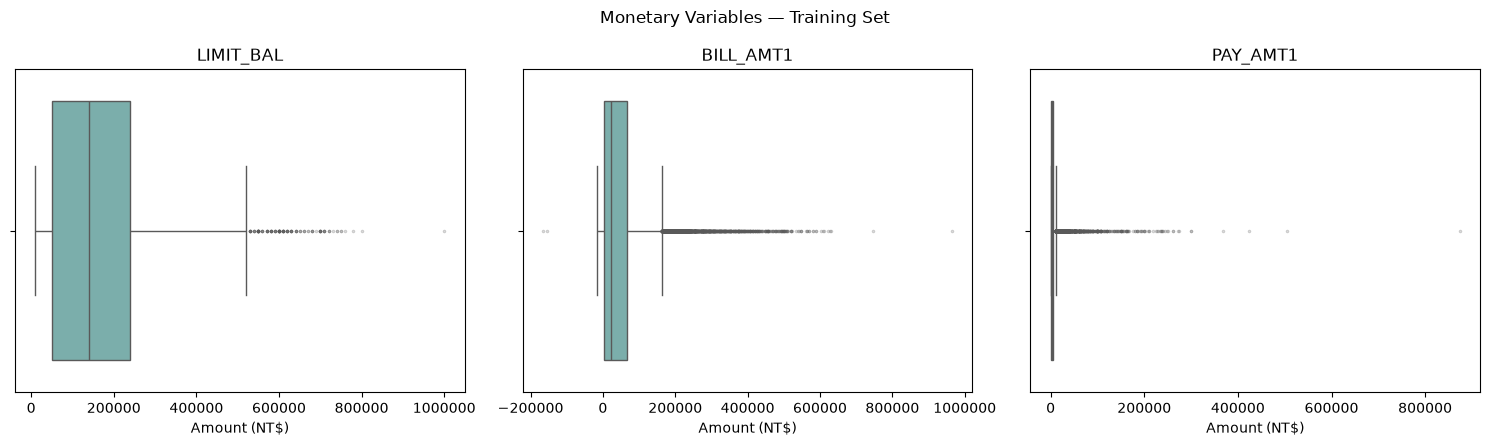

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Start the list of monetary variables with the credit limit
money_columns = ["LIMIT_BAL"]

# range(1, 7) generates integers from 1 to 6
# Each formatted name runs from BILL_AMT1 to BILL_AMT6
for i in range(1, 7):
    money_columns.append(f"BILL_AMT{i}")

# Add the payment amounts for the previous six months
for i in range(1, 7):
    money_columns.append(f"PAY_AMT{i}")

# Select the monetary variables from the cleaned training set
money_data = X_train_clean[money_columns]

# Summarise monetary values and count negative and zero entries
money_summary = pd.DataFrame({
    "Minimum": money_data.min(),
    "Median": money_data.median(),
    "Mean": money_data.mean(),
    "99th percentile": money_data.quantile(0.99),
    "Maximum": money_data.max(),
    "Negative count": (money_data < 0).sum(),
    "Zero count": (money_data == 0).sum()
})

# Round the displayed results to two decimal places
display(money_summary.round(2))


# Select three representative variables for visualisation
selected_columns = ["LIMIT_BAL", "BILL_AMT1", "PAY_AMT1"]

# Create three plotting areas, each with its own monetary scale
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# Draw a horizontal boxplot for each selected variable
for ax, column in zip(axes, selected_columns):
    sns.boxplot(
        x=X_train_clean[column],
        ax=ax,
        color="#72B7B2",
        flierprops={
            "marker": ".",       # Display outlier points as small dots
            "markersize": 3,     # Set the size of the dots
            "alpha": 0.3         # Use transparency to reduce overlap
        }
    )

    ax.set_title(column)
    ax.set_xlabel("Amount (NT$)")
    ax.ticklabel_format(axis="x", style="plain")

# Add an overall title and adjust the layout
fig.suptitle("Monetary Variables — Training Set")
fig.tight_layout()

# Create the figures folder if it does not already exist
Path("figures").mkdir(exist_ok=True)

# Save a high-resolution image for the report
fig.savefig(
    "figures/04_monetary_boxplots.png",
    dpi=300,
    bbox_inches="tight"
)

# Display the boxplots in the notebook
plt.show()

## Preparing Data for Logistic Regression

This step converts customer information into a suitable format for Logistic Regression, which will learn to predict whether a customer defaults next month.

### 1. Scale Numerical Features with RobustScaler

Numerical features have different scales. For example, a customer's age might be `35`, while their credit limit might be `200000`.

RobustScaler adjusts each feature using its median and interquartile range—the spread of the middle 50% of values. These scaling statistics are less sensitive to extreme values.

It preserves customer records and does not make the distributions normal.

### 2. Encode Categorical Features with One-Hot Encoding

One-Hot Encoding converts categories into separate binary columns.

For example, marital status can become columns such as “Is married” and “Is single”, where `1` means yes and `0` means no.

This avoids treating category codes as numerical quantities. We also treat the six repayment-status variables as categorical features, which is our modelling choice.

### 3. Combine Preprocessing and the Model in a Pipeline

The pipeline connects the steps:

**Customer features → Numerical scaling and categorical encoding → Logistic Regression**

Preprocessing rules are learned from the training data and then applied to the test data. This prevents test information from influencing model development.

In [14]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import RobustScaler, OneHotEncoder

# Specify the categorical features
# Include three customer categories and six months of repayment status
categorical_columns = [
    "SEX", "EDUCATION", "MARRIAGE",
    "PAY_0", "PAY_2", "PAY_3",
    "PAY_4", "PAY_5", "PAY_6"
]

# Treat the remaining features as numerical:
# age, credit limit, bill amounts and payment amounts
numeric_columns = [
    column for column in X_train_clean.columns
    if column not in categorical_columns
]

# Apply different preprocessing methods to each feature group
preprocessor = ColumnTransformer(
    transformers=[
        # Numerical features: scale using the median and interquartile range
        ("num", RobustScaler(), numeric_columns),

        # Categorical features: convert categories into separate 0/1 columns
        # handle_unknown="ignore": handle unseen categories without an error
        # sparse_output=False: return a dense numerical array
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_columns
        )
    ]
)

# Check the feature counts: expect 14 numerical and 9 categorical features
print("Numeric features:", len(numeric_columns))
print("Categorical features:", len(categorical_columns))

Numeric features: 14
Categorical features: 9


In [15]:
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import (
    make_scorer,
    precision_score,
    recall_score,
    f1_score
)

# Define the pipeline: preprocess the features, then fit the classifier
lr_pipeline = Pipeline([
    ("preprocess", preprocessor),

    # max_iter sets the maximum number of solver iterations
    # It allows more time to converge, rather than requiring 2000 iterations
    ("model", LogisticRegression(max_iter=2000))
])

# Use stratified five-fold cross-validation
# Each fold maintains approximately the original class proportions
# Fix the random seed to make the shuffled splits reproducible
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Define the evaluation metrics
# Precision, recall and F1 focus on the default class, labelled 1
# zero_division=0 returns 0 when a metric has an undefined denominator
scoring = {
    "Accuracy": "accuracy",
    "ROC_AUC": "roc_auc",
    "Precision": make_scorer(
        precision_score, pos_label=1, zero_division=0
    ),
    "Recall": make_scorer(
        recall_score, pos_label=1, zero_division=0
    ),
    "F1": make_scorer(
        f1_score, pos_label=1, zero_division=0
    )
}

# Perform cross-validation using only the training set
# n_jobs=-1 allows parallel processing using all available CPU cores
# error_score="raise" displays the error if fitting or scoring fails
lr_cv_results = cross_validate(
    lr_pipeline,
    X_train_clean,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1,
    error_score="raise"
)

# Calculate the mean and sample standard deviation across the five folds
summary_rows = []

for metric in scoring:
    # "test" in cross_validate refers to each validation fold
    # The separately reserved X_test_clean is not used here
    fold_scores = lr_cv_results[f"test_{metric}"]

    summary_rows.append({
        "Metric": metric,
        "Mean": fold_scores.mean(),
        "Std": fold_scores.std(ddof=1)
    })

lr_summary = pd.DataFrame(summary_rows).set_index("Metric")

print("Logistic Regression — 5-fold validation results")
display(lr_summary.round(4))

Logistic Regression — 5-fold validation results


,Mean,Std
Metric,,
Accuracy,0.8205,0.0023
ROC_AUC,0.7690,0.0068
Precision,0.6796,0.0184
Recall,0.3581,0.0089
F1,0.4688,0.0054


### Interpreting the Evaluation Metrics

- **Accuracy:** What proportion of all predictions is correct?

- **ROC-AUC:** How well does the model rank customers who default above those who do not?

- **Precision:** Among customers predicted to default, what proportion actually defaults?

- **Recall:** Among customers who actually default, what proportion does the model identify?

- **F1-score:** What is the harmonic mean of precision and recall?

- **Standard deviation (Std):** How much do the results vary across the five validation folds? A smaller value indicates more consistent scores across these folds.
--------------------------------------------------------------------------------------------------------------------------------------------
- **Accuracy: 82.05%** — 4.17 percentage points higher than the approximately 77.88% baseline obtained by predicting every customer as non-default.

- **ROC-AUC: 0.7690** — Indicates some ability to rank customers by default risk; it does not mean 76.9% accuracy.

- **Precision: 67.96%** — Approximately 68% of customers predicted to default actually defaulted.

- **Recall: 35.81%** — The model identified approximately 36% of customers who actually defaulted.

- **F1: 46.88%** — The harmonic mean of precision and recall.

### Model Comparison Approach

ROC-AUC is currently the primary comparison metric. Precision, recall and F1-score for the default class are also examined.

These results represent the initial Logistic Regression baseline. The other two models will also be trained, and all three models will subsequently undergo hyperparameter tuning.

### Viva Explanation

“I combine preprocessing and Logistic Regression in a pipeline and use stratified five-fold cross-validation. This ensures that preprocessing is fitted within each training fold. The separate test set remains reserved for final evaluation.”

In [16]:
import pandas as pd

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate
from sklearn.ensemble import (
    RandomForestClassifier,
    HistGradientBoostingClassifier
)

# Store the configurations of the three base models.
# Reuse the Logistic Regression pipeline defined in the previous cell.
base_models = {
    "Logistic Regression": lr_pipeline,

    "Random Forest": Pipeline([
        # Clone the preprocessing configuration so each model has its own instance.
        ("preprocess", clone(preprocessor)),

        ("model", RandomForestClassifier(
            n_estimators=100,  # Use 100 trees for the initial model.
            random_state=42,   # Fix the model's internal random processes.
            n_jobs=1           # Parallelism is handled by cross-validation below.
        ))
    ]),

    "HistGradientBoosting": Pipeline([
        ("preprocess", clone(preprocessor)),

        # Use default settings for the main hyperparameters.
        # Hyperparameter tuning will be performed later in Part E.
        ("model", HistGradientBoostingClassifier(
            random_state=42
        ))
    ])
}

# Store the previously calculated Logistic Regression results.
# Only the other two models need to be evaluated in this cell.
base_cv_results = {
    "Logistic Regression": lr_cv_results
}

# Use the same five-fold splits and scoring metrics as Logistic Regression.
for model_name in ["Random Forest", "HistGradientBoosting"]:
    print(f"Evaluating {model_name}...")

    base_cv_results[model_name] = cross_validate(
        base_models[model_name],
        X_train_clean,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        error_score="raise"
    )


# Create separate summaries for the means and standard deviations.
mean_rows = []
std_rows = []

# items() returns each model name and its cross-validation results.
for model_name, results in base_cv_results.items():
    mean_row = {"Model": model_name}
    std_row = {"Model": model_name}

    # Summarise Accuracy, ROC-AUC, Precision, Recall and F1.
    for metric in scoring:
        fold_scores = results[f"test_{metric}"]

        mean_row[metric] = fold_scores.mean()
        std_row[metric] = fold_scores.std(ddof=1)

    mean_rows.append(mean_row)
    std_rows.append(std_row)

# Convert the records into tables, using model names as the row index.
base_cv_mean = pd.DataFrame(mean_rows).set_index("Model")
base_cv_std = pd.DataFrame(std_rows).set_index("Model")

print("\nFive-fold validation means:")
display(base_cv_mean.round(4))

print("\nFive-fold validation standard deviations:")
display(base_cv_std.round(4))

Evaluating Random Forest...
Evaluating HistGradientBoosting...

Five-fold validation means:


,Accuracy,ROC_AUC,Precision,Recall,F1
Model,,,,,
Logistic Regression,0.8205,0.7690,0.6796,0.3581,0.4688
Random Forest,0.8183,0.7672,0.6576,0.3728,0.4758
HistGradientBoosting,0.8219,0.7830,0.6787,0.3703,0.4792



Five-fold validation standard deviations:


,Accuracy,ROC_AUC,Precision,Recall,F1
Model,,,,,
Logistic Regression,0.0023,0.0068,0.0184,0.0089,0.0054
Random Forest,0.0022,0.0030,0.0107,0.0022,0.0043
HistGradientBoosting,0.0014,0.0058,0.0074,0.0041,0.0040


- **Independent preprocessing:** Each model receives a cloned preprocessor with the same settings but an independent fitted state. This prevents fitting one pipeline from changing another pipeline’s preprocessing.
- **Cloning behaviour:** `clone()` copies the configuration, not previously learned information. Explicit cloning is optional here because `cross_validate()` already clones each pipeline for every fold.
- **Consistent evaluation:** All three models use the same five-fold cross-validation splits (`cv=cv`) and scoring metrics (`scoring=scoring`) for a fair comparison.
- **Shared metrics:** Accuracy, ROC-AUC, Precision, Recall and F1 are calculated for every model. The metrics are the same, but the resulting scores may differ.



# Part E — Hyperparameter Optimisation

Each member tunes one model with the **same procedure**, so the results can be compared directly:

- the same training data (`X_train_clean`, `y_train`), the same preprocessing (`preprocessor`), the same five stratified folds (`cv`) and the same five metrics (`scoring`) as the baselines above;
- a coarse search first, then a finer grid around the best result, choosing the setting with the best **validation ROC-AUC**;
- training scores are recorded too, so overfitting can be checked;
- the test set is **not** used in Part E.

| Member | Model | Search |
|---|---|---|
| 1 | Logistic Regression | full grid (few settings, fast to train), then finer `C` |
| 2 | Random Forest | randomised search (40 combinations), then grid |
| 3 | HistGradientBoosting | randomised search (40 combinations), then grid |

Tables are saved to `results/` and figures to `figures/`.

In [17]:
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.model_selection import (
    GridSearchCV,
    RandomizedSearchCV,
    cross_validate,
    cross_val_predict,
    validation_curve,
)

Path("results").mkdir(exist_ok=True)
Path("figures").mkdir(exist_ok=True)

# Random combinations tried by the two tree models (reduce to 20 if too slow)
N_ITER = 40


def search_summary(search, top=10):
    """Return the top configurations of a search as a readable table."""
    results = pd.DataFrame(search.cv_results_)
    n_folds = search.n_splits_

    param_columns = [c for c in results.columns if c.startswith("param_")]
    table = results[param_columns].copy()
    table.columns = [c.replace("param_model__", "") for c in param_columns]

    val_folds = results[[f"split{i}_test_ROC_AUC" for i in range(n_folds)]]
    table["Val ROC_AUC"] = results["mean_test_ROC_AUC"]
    table["Val ROC_AUC std"] = val_folds.std(axis=1, ddof=1)
    table["Train ROC_AUC"] = results["mean_train_ROC_AUC"]
    table["Gap"] = table["Train ROC_AUC"] - table["Val ROC_AUC"]   # large gap = overfitting
    table["Val F1"] = results["mean_test_F1"]
    table["Val Recall"] = results["mean_test_Recall"]
    table["Fit time (s)"] = results["mean_fit_time"]
    table["Rank"] = results["rank_test_ROC_AUC"]
    return table.sort_values("Rank").head(top)


def neighbours(value, ordered_options):
    """Return the value together with the values on either side of it."""
    position = ordered_options.index(value)
    return ordered_options[max(0, position - 1): position + 2]


def baseline_vs_tuned(label, baseline_pipeline, baseline_cv, tuned_cv):
    """Compare the five validation metrics and the train-validation gap."""
    rows = []
    for metric in scoring:
        b, t = baseline_cv[f"test_{metric}"], tuned_cv[f"test_{metric}"]
        rows.append({"Metric": metric,
                     "Baseline mean": b.mean(), "Baseline std": b.std(ddof=1),
                     "Tuned mean": t.mean(), "Tuned std": t.std(ddof=1),
                     "Change": t.mean() - b.mean()})
    comparison = pd.DataFrame(rows).set_index("Metric")

    # The baseline results above did not store training scores, so the
    # baseline training ROC-AUC is calculated here on the same folds
    baseline_train = cross_validate(
        baseline_pipeline, X_train_clean, y_train, cv=cv,
        scoring={"ROC_AUC": "roc_auc"}, return_train_score=True,
        n_jobs=-1, error_score="raise",
    )
    b_train, b_val = baseline_train["train_ROC_AUC"].mean(), baseline_cv["test_ROC_AUC"].mean()
    t_train, t_val = tuned_cv["train_ROC_AUC"].mean(), tuned_cv["test_ROC_AUC"].mean()
    fit_check = pd.DataFrame({
        "Train ROC_AUC": [b_train, t_train],
        "Validation ROC_AUC": [b_val, t_val],
        "Gap (train - val)": [b_train - b_val, t_train - t_val],
        "Mean fit time per fold (s)": [baseline_cv["fit_time"].mean(), tuned_cv["fit_time"].mean()],
    }, index=[f"Baseline {label}", f"Tuned {label}"])
    return comparison, fit_check


def plot_validation_curve(pipeline, param, values, chosen, title, xlabel, path):
    """Training and validation ROC-AUC across one hyperparameter."""
    train_scores, val_scores = validation_curve(
        pipeline, X_train_clean, y_train, param_name=param, param_range=values,
        cv=cv, scoring="roc_auc", n_jobs=-1,
    )
    train_mean, train_std = train_scores.mean(axis=1), train_scores.std(axis=1, ddof=1)
    val_mean, val_std = val_scores.mean(axis=1), val_scores.std(axis=1, ddof=1)

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(values, train_mean, marker="o", color="#4C78A8", label="Training ROC-AUC")
    ax.fill_between(values, train_mean - train_std, train_mean + train_std, color="#4C78A8", alpha=0.15)
    ax.plot(values, val_mean, marker="o", color="#E45756", label="Validation ROC-AUC")
    ax.fill_between(values, val_mean - val_std, val_mean + val_std, color="#E45756", alpha=0.15)
    ax.axvline(chosen, color="grey", linestyle="--", label=f"Selected = {chosen:g}")
    ax.set_xscale("log")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("ROC-AUC (5-fold mean ± std)")
    ax.set_title(title)
    ax.legend()
    fig.tight_layout()
    fig.savefig(path, dpi=300, bbox_inches="tight")
    plt.show()
    return pd.DataFrame({"Train ROC_AUC": train_mean, "Validation ROC_AUC": val_mean,
                         "Gap": train_mean - val_mean}, index=pd.Index(values, name=param.replace("model__", "")))


def save_handover(prefix, label, best_params, tuned_pipeline, tuned_cv, extra=None):
    """Save the tuned settings, out-of-fold probabilities and a summary row."""
    clean_params = {name.replace("model__", ""): (v.item() if hasattr(v, "item") else v)
                    for name, v in best_params.items()}
    clean_params.update(extra or {})
    with open(f"results/{prefix}_best_params.json", "w") as f:
        json.dump(clean_params, f, indent=2)

    oof = cross_val_predict(tuned_pipeline, X_train_clean, y_train, cv=cv,
                            method="predict_proba", n_jobs=-1)[:, 1]
    pd.DataFrame({"y_true": y_train, f"{prefix}_proba": oof},
                 index=X_train_clean.index).to_csv(f"results/{prefix}_oof_proba.csv")

    summary = pd.DataFrame({m: [tuned_cv[f"test_{m}"].mean()] for m in scoring},
                           index=pd.Index([f"{label} (tuned)"], name="Model"))
    summary.to_csv(f"results/{prefix}_tuned_cv_summary.csv")
    print(f"Tuned {label} parameters:")
    print(json.dumps(clean_params, indent=2))
    display(summary.round(4))

## Part E1 — Logistic Regression (Member 1)

Logistic Regression has few hyperparameters and trains in about a second, so **every combination** is tried (grid search) instead of a random sample:

- `C` — the inverse of the regularisation strength; a small `C` keeps the coefficients small and the model simple;
- `l1_ratio` — 0 = L2 (ridge) penalty, 1 = L1 (lasso) penalty, which can set coefficients to exactly zero;
- `class_weight` — `"balanced"` gives the default class more weight.

The `liblinear` solver is used because it supports both L1 and L2 for a binary problem.

In [18]:
lr_tune_pipeline = Pipeline([
    ("preprocess", clone(preprocessor)),
    ("model", LogisticRegression(solver="liblinear", max_iter=2000)),
])

lr_param_grid = {
    "model__C": [0.001, 0.01, 0.1, 1, 10, 100],
    "model__l1_ratio": [0.0, 1.0],              # 0 = L2, 1 = L1
    "model__class_weight": [None, "balanced"],
}

lr_grid_search = GridSearchCV(
    estimator=lr_tune_pipeline,
    param_grid=lr_param_grid,
    scoring=scoring,
    refit="ROC_AUC",          # choose by validation ROC-AUC
    cv=cv,                    # same five folds as the other models
    return_train_score=True,
    n_jobs=-1,
    error_score="raise",
)

start = time.perf_counter()
lr_grid_search.fit(X_train_clean, y_train)
lr_grid_time = time.perf_counter() - start

print(f"Stage 1 finished in {lr_grid_time:.1f} seconds")
print("Best validation ROC-AUC:", round(lr_grid_search.best_score_, 4))
display(search_summary(lr_grid_search, top=10).round(4))
pd.DataFrame(lr_grid_search.cv_results_).to_csv("results/lr_grid_search_cv_results.csv", index=False)

Stage 1 finished in 17.8 seconds
Best validation ROC-AUC: 0.7701


,C,class_weight,l1_ratio,Val ROC_AUC,Val ROC_AUC std,Train ROC_AUC,Gap,Val F1,Val Recall,Fit time (s),Rank
4,0.01,NaN,0.0,0.7701,0.0061,0.7740,0.0040,0.4395,0.3249,0.5683,1
11,0.10,balanced,1.0,0.7697,0.0066,0.7745,0.0048,0.5349,0.5811,1.7287,2
10,0.10,balanced,0.0,0.7697,0.0066,0.7751,0.0053,0.5342,0.5803,1.0856,3
6,0.01,balanced,0.0,0.7696,0.0061,0.7741,0.0045,0.5326,0.5788,0.5611,4
15,1.00,balanced,1.0,0.7695,0.0067,0.7752,0.0056,0.5329,0.5800,7.4348,5
8,0.10,NaN,0.0,0.7695,0.0067,0.7746,0.0051,0.4681,0.3575,0.8100,6
14,1.00,balanced,0.0,0.7695,0.0067,0.7752,0.0058,0.5328,0.5800,2.1419,7
9,0.10,NaN,1.0,0.7692,0.0063,0.7737,0.0045,0.4641,0.3534,0.9587,8
13,1.00,NaN,1.0,0.7691,0.0068,0.7745,0.0055,0.4684,0.3577,2.6742,9
18,10.00,balanced,0.0,0.7691,0.0068,0.7755,0.0064,0.5326,0.5792,3.4844,10


### Stage 2 — Finer grid for `C`

The other settings stay at their best values; `C` is searched half a decade either side of the best value, in quarter-decade steps.

In [19]:
best_stage1 = lr_grid_search.best_params_
best_c = best_stage1["model__C"]
fine_c = sorted({round(float(best_c * 10 ** p), 6) for p in (-0.5, -0.25, 0, 0.25, 0.5)})

lr_fine_grid = {name: [value] for name, value in best_stage1.items()}
lr_fine_grid["model__C"] = fine_c
print("C values:", fine_c)

lr_fine_search = GridSearchCV(
    estimator=lr_tune_pipeline, param_grid=lr_fine_grid, scoring=scoring,
    refit="ROC_AUC", cv=cv, return_train_score=True, n_jobs=-1, error_score="raise",
)
start = time.perf_counter()
lr_fine_search.fit(X_train_clean, y_train)
lr_fine_time = time.perf_counter() - start

print("Stage 1 best ROC-AUC:", round(lr_grid_search.best_score_, 4))
print("Stage 2 best ROC-AUC:", round(lr_fine_search.best_score_, 4))
display(search_summary(lr_fine_search, top=5).round(4))
pd.DataFrame(lr_fine_search.cv_results_).to_csv("results/lr_fine_search_cv_results.csv", index=False)

C values: [0.003162, 0.005623, 0.01, 0.017783, 0.031623]
Stage 1 best ROC-AUC: 0.7701
Stage 2 best ROC-AUC: 0.7701


,C,class_weight,l1_ratio,Val ROC_AUC,Val ROC_AUC std,Train ROC_AUC,Gap,Val F1,Val Recall,Fit time (s),Rank
3,0.0178,None,0.0,0.7701,0.0062,0.7744,0.0043,0.4576,0.3449,0.7529,1
2,0.0100,None,0.0,0.7701,0.0061,0.7740,0.0040,0.4395,0.3249,0.7457,2
4,0.0316,None,0.0,0.7700,0.0065,0.7746,0.0046,0.4659,0.3549,0.7468,3
1,0.0056,None,0.0,0.7697,0.0061,0.7733,0.0036,0.4128,0.2961,0.5813,4
0,0.0032,None,0.0,0.7690,0.0061,0.7721,0.0031,0.3823,0.2660,0.5066,5


### Tuned Logistic Regression vs baseline

In [20]:
lr_best_params = lr_fine_search.best_params_
lr_tuned_pipeline = clone(lr_tune_pipeline).set_params(**lr_best_params)

lr_tuned_cv_results = cross_validate(
    lr_tuned_pipeline, X_train_clean, y_train, cv=cv, scoring=scoring,
    return_train_score=True, n_jobs=-1, error_score="raise",
)

lr_comparison, lr_fit_check = baseline_vs_tuned(
    "LR", base_models["Logistic Regression"], base_cv_results["Logistic Regression"], lr_tuned_cv_results
)
print("Logistic Regression — 5-fold validation: baseline vs tuned")
display(lr_comparison.round(4))
print("Overfitting and training-time check")
display(lr_fit_check.round(4))
lr_comparison.to_csv("results/lr_baseline_vs_tuned.csv")
lr_fit_check.to_csv("results/lr_fit_check.csv")

Logistic Regression — 5-fold validation: baseline vs tuned


,Baseline mean,Baseline std,Tuned mean,Tuned std,Change
Metric,,,,,
Accuracy,0.8205,0.0023,0.8192,0.0034,-0.0013
ROC_AUC,0.7690,0.0068,0.7701,0.0062,0.0011
Precision,0.6796,0.0184,0.6804,0.0177,0.0009
Recall,0.3581,0.0089,0.3449,0.0144,-0.0132
F1,0.4688,0.0054,0.4576,0.0138,-0.0112


Overfitting and training-time check


,Train ROC_AUC,Validation ROC_AUC,Gap (train - val),Mean fit time per fold (s)
Baseline LR,0.7746,0.7690,0.0056,0.5542
Tuned LR,0.7744,0.7701,0.0043,0.1625


### Validation curve — effect of `C`

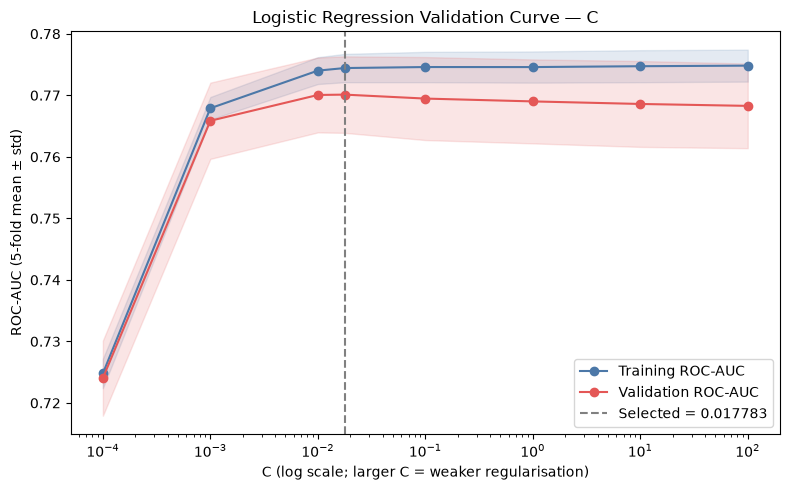

,Train ROC_AUC,Validation ROC_AUC,Gap
C,,,
0.000100,0.7248,0.7240,0.0008
0.001000,0.7679,0.7659,0.0020
0.010000,0.7740,0.7701,0.0040
0.017783,0.7744,0.7701,0.0043
0.100000,0.7746,0.7695,0.0051
1.000000,0.7746,0.7690,0.0056
10.000000,0.7747,0.7686,0.0061
100.000000,0.7748,0.7683,0.0065


In [21]:
chosen_c = lr_best_params["model__C"]
lr_curve = plot_validation_curve(
    lr_tuned_pipeline, "model__C", sorted({0.0001, 0.001, 0.01, 0.1, 1, 10, 100, chosen_c}), chosen_c,
    "Logistic Regression Validation Curve — C",
    "C (log scale; larger C = weaker regularisation)",
    "figures/07_lr_validation_curve_C.png",
)
display(lr_curve.round(4))
lr_curve.to_csv("results/lr_validation_curve.csv")

### Coefficients of the tuned Logistic Regression

A positive coefficient raises the predicted probability of default. Numerical features were scaled with RobustScaler, so their coefficients are per interquartile range; one-hot columns keep every category, so compare categories within the same column (for example `PAY_0_2` against `PAY_0_0`).

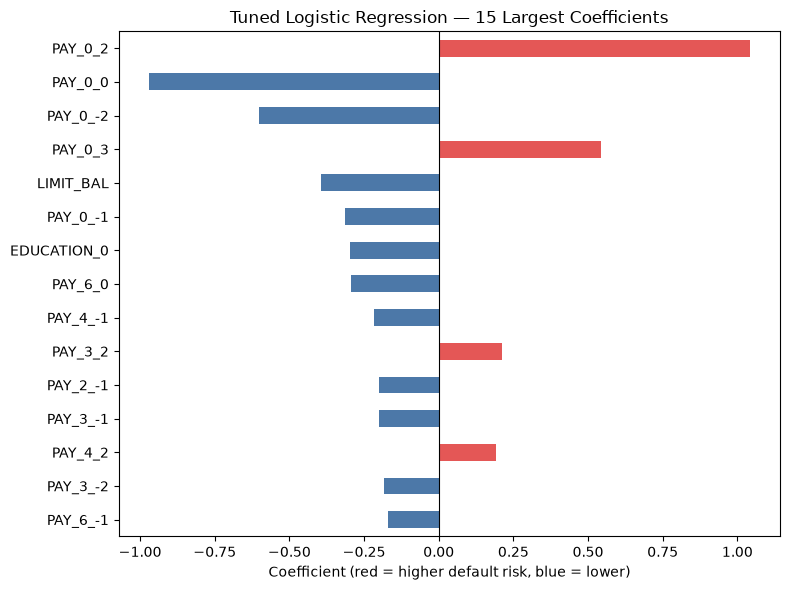

,Coefficient
PAY_0_2,1.0421
PAY_0_0,-0.9711
PAY_0_-2,-0.6018
PAY_0_3,0.5437
LIMIT_BAL,-0.3958
PAY_0_-1,-0.3127
EDUCATION_0,-0.2984
PAY_6_0,-0.2941
PAY_4_-1,-0.2179
PAY_3_2,0.2108


Coefficients set to exactly zero (only with L1): 0 of 89


In [22]:
lr_final_model = clone(lr_tuned_pipeline).fit(X_train_clean, y_train)
feature_names = [name.replace("num__", "").replace("cat__", "")
                 for name in lr_final_model.named_steps["preprocess"].get_feature_names_out()]
coefficients = pd.Series(lr_final_model.named_steps["model"].coef_[0], index=feature_names)

top = coefficients.reindex(coefficients.abs().sort_values(ascending=False).index).head(15)
fig, ax = plt.subplots(figsize=(8, 6))
top.iloc[::-1].plot.barh(ax=ax, color=["#E45756" if v > 0 else "#4C78A8" for v in top.iloc[::-1]])
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Tuned Logistic Regression — 15 Largest Coefficients")
ax.set_xlabel("Coefficient (red = higher default risk, blue = lower)")
fig.tight_layout()
fig.savefig("figures/08_lr_coefficients.png", dpi=300, bbox_inches="tight")
plt.show()

display(top.round(4).to_frame("Coefficient"))
print(f"Coefficients set to exactly zero (only with L1): {int((coefficients == 0).sum())} of {len(coefficients)}")
coefficients.sort_values().to_csv("results/lr_coefficients.csv", header=["Coefficient"])

In [23]:
# Hand-over to Member 4
save_handover("lr", "Logistic Regression", lr_best_params, lr_tuned_pipeline, lr_tuned_cv_results,
              extra={"solver": "liblinear", "max_iter": 2000})
print(f"Total search time: {lr_grid_time + lr_fine_time:.1f} seconds")

Tuned Logistic Regression parameters:
{
  "C": 0.017783,
  "class_weight": null,
  "l1_ratio": 0.0,
  "solver": "liblinear",
  "max_iter": 2000
}


,Accuracy,ROC_AUC,Precision,Recall,F1
Model,,,,,
Logistic Regression (tuned),0.8192,0.7701,0.6804,0.3449,0.4576


Total search time: 19.2 seconds


### Logistic Regression — findings

- **Best settings:** `C ≈ 0.018` with an L2 penalty and no class weight: fairly strong regularisation.
- **Improvement:** validation ROC-AUC rose only from 0.7690 to 0.7701, smaller than the fold standard deviation (≈ 0.006). The validation curve is flat for `C ≥ 0.01`, so a linear model has reached its limit and tuning cannot add much.
- **Overfitting:** the train–validation gap is very small (0.004), as expected from a simple model.
- **Class weight:** `balanced` gives almost the same ROC-AUC (0.770) but much higher recall (≈ 0.58 vs 0.34), because weighting mainly shifts the probabilities rather than the ranking.
- **Interpretation:** the largest coefficients are `PAY_0 = 2` (+1.04, two months late), `PAY_0 = 0` (−0.97) and `LIMIT_BAL` (−0.40), which matches the EDA.

## Part E — Hyperparameter Optimisation: Random Forest (Member 2)

**Goal:** tune the Random Forest base model under exactly the same conditions as the other two base models, so all tuned models can be compared fairly.

**Fixed conditions (shared with the team)**
- **Data:** `X_train_clean` and `y_train` only. The test set is **not** used here; it stays reserved for the final evaluation.
- **Folds:** the same `cv` object (stratified 5-fold, `random_state=42`), so every model is scored on identical folds.
- **Metrics:** the same `scoring` dictionary. **ROC-AUC** (the team's primary metric) selects the best configuration (`refit="ROC_AUC"`).
- **Pipeline:** the same preprocessing as the baseline Random Forest, so any change in performance comes from the hyperparameters only.

**Search strategy (coarse → fine)**
1. **Randomised search:** 40 random combinations from a wide search space.
2. **Grid search:** a small grid around the best `max_depth` and `min_samples_leaf` from step 1, the two settings that mainly control tree complexity.

**Run time:** about 15–30 minutes for this whole section on a typical laptop. If it is too slow, reduce `n_iter` from 40 to 20.

| Hyperparameter | Values searched | Role |
|---|---|---|
| `n_estimators` | 100, 200, 300, 500 | Number of trees |
| `max_depth` | 8, 12, 16, 20, 30, None | Maximum depth of each tree |
| `min_samples_leaf` | 1, 2, 5, 10, 20 | Minimum customers in a leaf |
| `min_samples_split` | 2, 5, 10, 20 | Minimum customers needed to split a node |
| `max_features` | sqrt, log2, 0.2, 0.3 | Features considered at each split |
| `class_weight` | None, balanced, balanced_subsample | Extra weight for the minority (default) class |
| `max_samples` | None, 0.5, 0.8 | Size of each tree's bootstrap sample |

In [24]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.model_selection import RandomizedSearchCV

# Folder for result tables that Member 4 can reuse
Path("results").mkdir(exist_ok=True)

# Start from the baseline Random Forest pipeline defined above
# (same preprocessing, same random_state=42)
rf_pipeline = clone(base_models["Random Forest"])

# Search space
# The prefix "model__" points to the "model" step inside the pipeline
rf_param_distributions = {
    "model__n_estimators": [100, 200, 300, 500],
    "model__max_depth": [8, 12, 16, 20, 30, None],      # None = grow until leaves are pure
    "model__min_samples_leaf": [1, 2, 5, 10, 20],
    "model__min_samples_split": [2, 5, 10, 20],
    "model__max_features": ["sqrt", "log2", 0.2, 0.3],  # 0.3 = 30% of the features
    "model__class_weight": [None, "balanced", "balanced_subsample"],
    "model__max_samples": [None, 0.5, 0.8],             # None = bootstrap sample of full size
}

# Randomised search: try 40 random combinations
# Uses the shared cv folds and scoring metrics from the baseline section
rf_random_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=rf_param_distributions,
    n_iter=N_ITER,             # Number of combinations sampled
    scoring=scoring,           # Accuracy, ROC_AUC, Precision, Recall, F1
    refit="ROC_AUC",           # Choose the best combination by validation ROC-AUC
    cv=cv,                     # Same five folds as the other models
    return_train_score=True,   # Also record training scores to check overfitting
    n_jobs=-1,                 # Use all CPU cores (the forest itself uses n_jobs=1)
    random_state=42,           # Makes the sampled combinations reproducible
    error_score="raise",
)

print(f"Running randomised search: {N_ITER} combinations x 5 folds ...")
start = time.perf_counter()
rf_random_search.fit(X_train_clean, y_train)
rf_random_time = time.perf_counter() - start

print(f"Finished in {rf_random_time / 60:.1f} minutes")
print("Best validation ROC-AUC:", round(rf_random_search.best_score_, 4))
print("Best parameters:")
for name, value in rf_random_search.best_params_.items():
    print(f"  {name.replace('model__', '')}: {value}")

Running randomised search: 40 combinations x 5 folds ...
Finished in 2.9 minutes
Best validation ROC-AUC: 0.7859
Best parameters:
  n_estimators: 500
  min_samples_split: 10
  min_samples_leaf: 20
  max_samples: 0.8
  max_features: 0.3
  max_depth: 30
  class_weight: balanced


In [25]:
def search_summary(search, top=10):
    """Return the top configurations of a search as a readable table."""
    results = pd.DataFrame(search.cv_results_)
    n_folds = search.n_splits_

    # Hyperparameter columns, shown without the "param_model__" prefix
    param_columns = [c for c in results.columns if c.startswith("param_")]
    table = results[param_columns].copy()
    table.columns = [c.replace("param_model__", "") for c in param_columns]

    # Sample standard deviation (ddof=1), consistent with the baseline tables
    val_folds = results[[f"split{i}_test_ROC_AUC" for i in range(n_folds)]]

    table["Val ROC_AUC"] = results["mean_test_ROC_AUC"]
    table["Val ROC_AUC std"] = val_folds.std(axis=1, ddof=1)
    table["Train ROC_AUC"] = results["mean_train_ROC_AUC"]
    # Gap = training score minus validation score; a large gap indicates overfitting
    table["Gap"] = table["Train ROC_AUC"] - table["Val ROC_AUC"]
    table["Val F1"] = results["mean_test_F1"]
    table["Val Recall"] = results["mean_test_Recall"]
    table["Fit time (s)"] = results["mean_fit_time"]
    table["Rank"] = results["rank_test_ROC_AUC"]

    return table.sort_values("Rank").head(top)


rf_random_table = search_summary(rf_random_search, top=10)
print("Randomised search — top 10 configurations by validation ROC-AUC")
display(rf_random_table.round(4))

# Save all 40 combinations for the report appendix
pd.DataFrame(rf_random_search.cv_results_).to_csv(
    "results/rf_random_search_cv_results.csv", index=False
)

Randomised search — top 10 configurations by validation ROC-AUC


,n_estimators,min_samples_split,min_samples_leaf,max_samples,max_features,max_depth,class_weight,Val ROC_AUC,Val ROC_AUC std,Train ROC_AUC,Gap,Val F1,Val Recall,Fit time (s),Rank
32,500,10,20,0.8,0.3,30,balanced,0.7859,0.0060,0.8888,0.1029,0.5443,0.6163,30.3760,1
35,200,10,20,0.5,0.2,30,balanced,0.7856,0.0052,0.8593,0.0737,0.5450,0.6242,6.4255,2
30,500,2,20,None,sqrt,None,balanced,0.7852,0.0054,0.8673,0.0821,0.5447,0.6205,16.8053,3
27,300,2,10,None,sqrt,30,NaN,0.7851,0.0042,0.9105,0.1253,0.4670,0.3554,12.0910,4
6,300,2,10,None,0.2,None,balanced_subsample,0.7850,0.0049,0.9367,0.1517,0.5438,0.5591,19.4476,5
28,300,5,5,0.8,sqrt,20,balanced,0.7850,0.0049,0.9423,0.1573,0.5437,0.5922,10.0188,6
22,200,20,5,0.5,sqrt,20,NaN,0.7843,0.0046,0.8943,0.1100,0.4671,0.3552,5.0075,7
0,500,2,5,0.8,log2,30,balanced_subsample,0.7842,0.0054,0.9249,0.1407,0.5447,0.5542,13.8964,8
31,100,10,20,0.5,sqrt,20,balanced,0.7840,0.0051,0.8405,0.0565,0.5415,0.6254,2.2806,9
23,500,10,10,0.8,0.3,12,NaN,0.7839,0.0045,0.8745,0.0906,0.4718,0.3607,36.2346,10


### Stage 2 — Grid search around the best randomised result

The randomised search only tried values from a coarse list. Here every other setting stays fixed at the best randomised value, and `max_depth` and `min_samples_leaf` are searched over their neighbouring values on a finer scale (3 × 3 = up to 9 combinations).

In [26]:
from sklearn.model_selection import GridSearchCV


def neighbours(value, ordered_options):
    """Return the value together with the values on either side of it."""
    position = ordered_options.index(value)
    return ordered_options[max(0, position - 1): position + 2]


best_random = rf_random_search.best_params_

# Finer scales; they contain every value used in the randomised search
depth_options = [6, 8, 10, 12, 14, 16, 18, 20, 25, 30, None]  # None = unlimited (deepest)
leaf_options = [1, 2, 3, 5, 7, 10, 15, 20, 30]

# Fix all parameters at their best randomised values ...
rf_param_grid = {name: [value] for name, value in best_random.items()}

# ... then refine the two complexity parameters
rf_param_grid["model__max_depth"] = neighbours(
    best_random["model__max_depth"], depth_options
)
rf_param_grid["model__min_samples_leaf"] = neighbours(
    best_random["model__min_samples_leaf"], leaf_options
)

print("max_depth values:", rf_param_grid["model__max_depth"])
print("min_samples_leaf values:", rf_param_grid["model__min_samples_leaf"])

rf_grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_param_grid,
    scoring=scoring,
    refit="ROC_AUC",
    cv=cv,
    return_train_score=True,
    n_jobs=-1,
    error_score="raise",
)

start = time.perf_counter()
rf_grid_search.fit(X_train_clean, y_train)
rf_grid_time = time.perf_counter() - start

print(f"\nFinished in {rf_grid_time / 60:.1f} minutes")
print("Randomised search best ROC-AUC:", round(rf_random_search.best_score_, 4))
print("Grid search best ROC-AUC:      ", round(rf_grid_search.best_score_, 4))

display(search_summary(rf_grid_search, top=9).round(4))

pd.DataFrame(rf_grid_search.cv_results_).to_csv(
    "results/rf_grid_search_cv_results.csv", index=False
)

max_depth values: [25, 30, None]
min_samples_leaf values: [15, 20, 30]

Finished in 1.7 minutes
Randomised search best ROC-AUC: 0.7859
Grid search best ROC-AUC:       0.7859


,class_weight,max_depth,max_features,max_samples,min_samples_leaf,min_samples_split,n_estimators,Val ROC_AUC,Val ROC_AUC std,Train ROC_AUC,Gap,Val F1,Val Recall,Fit time (s),Rank
7,balanced,None,0.3,0.8,20,10,500,0.7859,0.0060,0.8888,0.1029,0.5443,0.6163,36.3086,1
4,balanced,30,0.3,0.8,20,10,500,0.7859,0.0060,0.8888,0.1029,0.5443,0.6163,35.3721,1
1,balanced,25,0.3,0.8,20,10,500,0.7859,0.0060,0.8888,0.1029,0.5446,0.6163,37.5222,3
2,balanced,25,0.3,0.8,30,10,500,0.7855,0.0058,0.8632,0.0777,0.5456,0.6227,33.6742,4
5,balanced,30,0.3,0.8,30,10,500,0.7855,0.0058,0.8632,0.0777,0.5455,0.6225,34.4355,5
8,balanced,None,0.3,0.8,30,10,500,0.7855,0.0058,0.8632,0.0777,0.5455,0.6225,34.2171,5
3,balanced,30,0.3,0.8,15,10,500,0.7854,0.0051,0.9081,0.1227,0.5429,0.6090,37.9290,7
6,balanced,None,0.3,0.8,15,10,500,0.7854,0.0051,0.9081,0.1227,0.5428,0.6088,37.7142,8
0,balanced,25,0.3,0.8,15,10,500,0.7853,0.0052,0.9080,0.1227,0.5426,0.6086,36.0981,9


### Final tuned Random Forest vs baseline

The final configuration is evaluated with `cross_validate` on the same folds and metrics as the baseline, so the two can be compared directly. Training scores are recorded as well to check for overfitting.

Note: choosing the best of many configurations by cross-validation makes its validation score slightly optimistic. The untouched test set (final evaluation by Member 4) provides the unbiased check.

In [27]:
from sklearn.model_selection import cross_validate

# Final hyperparameters = best result of the grid search
rf_best_params = rf_grid_search.best_params_

# Unfitted pipeline with the tuned settings (for Member 4's evaluation and ensemble)
rf_tuned_pipeline = clone(rf_pipeline).set_params(**rf_best_params)

# Tuned model: same folds, same metrics, plus training scores
rf_tuned_cv_results = cross_validate(
    rf_tuned_pipeline,
    X_train_clean,
    y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=True,
    n_jobs=-1,
    error_score="raise",
)

# The baseline results above did not store training scores,
# so the baseline training ROC-AUC is calculated here on the same folds
rf_baseline_train_check = cross_validate(
    base_models["Random Forest"],
    X_train_clean,
    y_train,
    cv=cv,
    scoring={"ROC_AUC": "roc_auc"},
    return_train_score=True,
    n_jobs=-1,
    error_score="raise",
)

# Compare the five validation metrics
rf_baseline_cv = base_cv_results["Random Forest"]
comparison_rows = []

for metric in scoring:
    baseline_scores = rf_baseline_cv[f"test_{metric}"]
    tuned_scores = rf_tuned_cv_results[f"test_{metric}"]

    comparison_rows.append({
        "Metric": metric,
        "Baseline mean": baseline_scores.mean(),
        "Baseline std": baseline_scores.std(ddof=1),
        "Tuned mean": tuned_scores.mean(),
        "Tuned std": tuned_scores.std(ddof=1),
        "Change": tuned_scores.mean() - baseline_scores.mean(),
    })

rf_comparison = pd.DataFrame(comparison_rows).set_index("Metric")

print("Random Forest — 5-fold validation: baseline vs tuned")
display(rf_comparison.round(4))

# Overfitting and training-time check
baseline_train_auc = rf_baseline_train_check["train_ROC_AUC"].mean()
baseline_val_auc = rf_baseline_cv["test_ROC_AUC"].mean()
tuned_train_auc = rf_tuned_cv_results["train_ROC_AUC"].mean()
tuned_val_auc = rf_tuned_cv_results["test_ROC_AUC"].mean()

rf_fit_check = pd.DataFrame({
    "Train ROC_AUC": [baseline_train_auc, tuned_train_auc],
    "Validation ROC_AUC": [baseline_val_auc, tuned_val_auc],
    "Gap (train - val)": [
        baseline_train_auc - baseline_val_auc,
        tuned_train_auc - tuned_val_auc,
    ],
    "Mean fit time per fold (s)": [
        rf_baseline_cv["fit_time"].mean(),
        rf_tuned_cv_results["fit_time"].mean(),
    ],
}, index=["Baseline RF", "Tuned RF"])

print("\nOverfitting and training-time check")
display(rf_fit_check.round(4))

rf_comparison.to_csv("results/rf_baseline_vs_tuned.csv")
rf_fit_check.to_csv("results/rf_fit_check.csv")

Random Forest — 5-fold validation: baseline vs tuned


,Baseline mean,Baseline std,Tuned mean,Tuned std,Change
Metric,,,,,
Accuracy,0.8183,0.0022,0.7717,0.0057,-0.0466
ROC_AUC,0.7672,0.0030,0.7859,0.0060,0.0187
Precision,0.6576,0.0107,0.4874,0.0099,-0.1702
Recall,0.3728,0.0022,0.6163,0.0063,0.2436
F1,0.4758,0.0043,0.5443,0.0078,0.0685



Overfitting and training-time check


,Train ROC_AUC,Validation ROC_AUC,Gap (train - val),Mean fit time per fold (s)
Baseline RF,1.0000,0.7672,0.2328,2.5456
Tuned RF,0.8888,0.7859,0.1029,16.0582


### Validation curve — effect of `min_samples_leaf`

All other hyperparameters stay at their tuned values. The curve shows how training and validation ROC-AUC change as the leaves become larger, which illustrates the overfitting/underfitting trade-off.

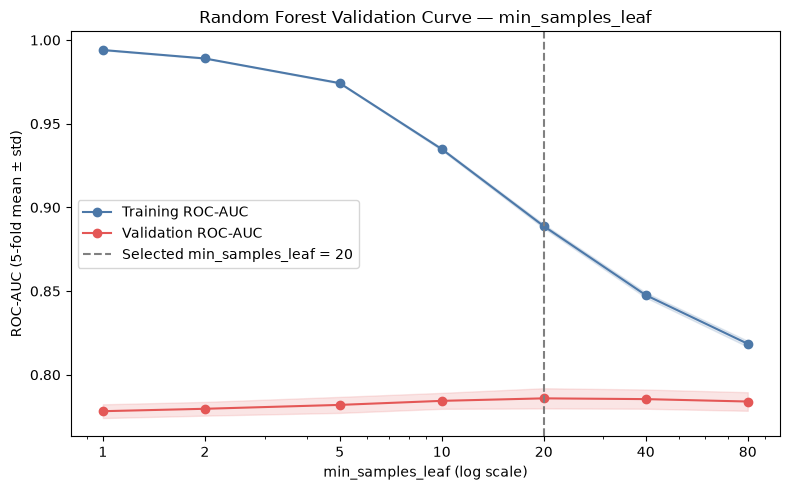

,Train ROC_AUC,Validation ROC_AUC,Gap
min_samples_leaf,,,
1,0.9940,0.7782,0.2158
2,0.9890,0.7797,0.2093
5,0.9743,0.7820,0.1923
10,0.9349,0.7844,0.1504
20,0.8888,0.7859,0.1029
40,0.8476,0.7855,0.0621
80,0.8185,0.7840,0.0345


In [28]:
import matplotlib.pyplot as plt
from sklearn.model_selection import validation_curve

# Values to plot, including the selected value so it appears on the curve
chosen_leaf = rf_best_params["model__min_samples_leaf"]
leaf_range = sorted({1, 2, 5, 10, 20, 40, 80, chosen_leaf})

train_scores, val_scores = validation_curve(
    rf_tuned_pipeline,
    X_train_clean,
    y_train,
    param_name="model__min_samples_leaf",
    param_range=leaf_range,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1,
)

train_mean, train_std = train_scores.mean(axis=1), train_scores.std(axis=1, ddof=1)
val_mean, val_std = val_scores.mean(axis=1), val_scores.std(axis=1, ddof=1)

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(leaf_range, train_mean, marker="o", color="#4C78A8", label="Training ROC-AUC")
ax.fill_between(leaf_range, train_mean - train_std, train_mean + train_std,
                color="#4C78A8", alpha=0.15)

ax.plot(leaf_range, val_mean, marker="o", color="#E45756", label="Validation ROC-AUC")
ax.fill_between(leaf_range, val_mean - val_std, val_mean + val_std,
                color="#E45756", alpha=0.15)

# Mark the selected value
ax.axvline(chosen_leaf, color="grey", linestyle="--",
           label=f"Selected min_samples_leaf = {chosen_leaf}")

ax.set_xscale("log")
ax.set_xticks(leaf_range)
ax.set_xticklabels(leaf_range)
ax.set_xlabel("min_samples_leaf (log scale)")
ax.set_ylabel("ROC-AUC (5-fold mean ± std)")
ax.set_title("Random Forest Validation Curve — min_samples_leaf")
ax.legend()
fig.tight_layout()

Path("figures").mkdir(exist_ok=True)
fig.savefig("figures/05_rf_validation_curve_min_samples_leaf.png", dpi=300, bbox_inches="tight")
plt.show()

display(pd.DataFrame({
    "min_samples_leaf": leaf_range,
    "Train ROC_AUC": train_mean,
    "Validation ROC_AUC": val_mean,
    "Gap": train_mean - val_mean,
}).set_index("min_samples_leaf").round(4))

### Feature importance of the tuned Random Forest

The tuned model is fitted once on the full training set. One-hot columns are summed back to their original feature (for example, all `PAY_0_*` columns → `PAY_0`).

Caveat: impurity-based importance tends to favour continuous features with many unique values (such as bill amounts), so it is used here as a rough guide only.

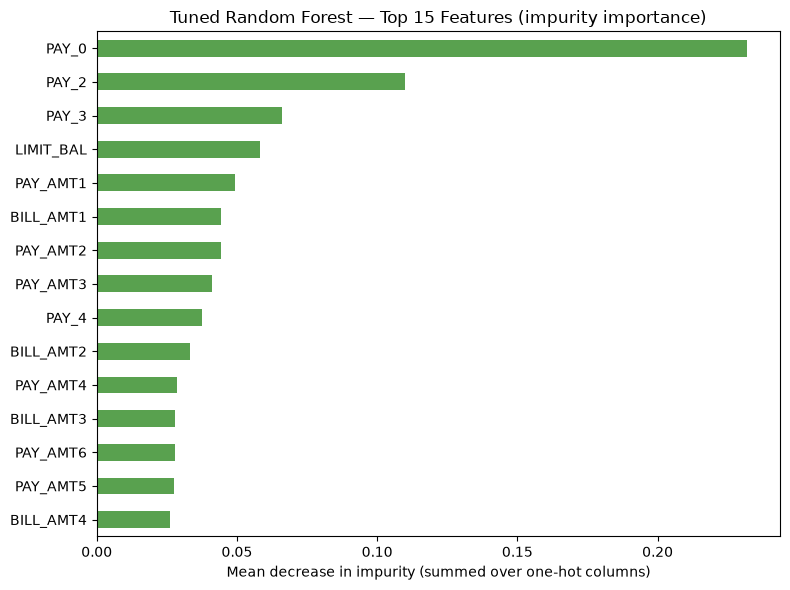

,Importance
PAY_0,0.2320
PAY_2,0.1101
PAY_3,0.0660
LIMIT_BAL,0.0582
PAY_AMT1,0.0494
BILL_AMT1,0.0445
PAY_AMT2,0.0443
PAY_AMT3,0.0411
PAY_4,0.0376
BILL_AMT2,0.0333


In [29]:
# Fit the tuned pipeline on the full training set
rf_final_model = clone(rf_tuned_pipeline)
rf_final_model.fit(X_train_clean, y_train)

fitted_preprocessor = rf_final_model.named_steps["preprocess"]
forest = rf_final_model.named_steps["model"]

# Map every transformed column back to its original feature
# ColumnTransformer outputs the numerical columns first, then the one-hot columns
encoder = fitted_preprocessor.named_transformers_["cat"]
original_feature = list(numeric_columns)
for column, categories in zip(categorical_columns, encoder.categories_):
    original_feature += [column] * len(categories)

assert len(original_feature) == len(forest.feature_importances_)

rf_importance = (
    pd.Series(forest.feature_importances_, index=original_feature)
    .groupby(level=0)
    .sum()
    .sort_values(ascending=False)
)

top_n = 15
fig, ax = plt.subplots(figsize=(8, 6))
rf_importance.head(top_n).iloc[::-1].plot.barh(ax=ax, color="#59A14F")
ax.set_title(f"Tuned Random Forest — Top {top_n} Features (impurity importance)")
ax.set_xlabel("Mean decrease in impurity (summed over one-hot columns)")
fig.tight_layout()
fig.savefig("figures/06_rf_feature_importance.png", dpi=300, bbox_inches="tight")
plt.show()

display(rf_importance.round(4).to_frame("Importance"))
rf_importance.to_csv("results/rf_feature_importance.csv", header=["Importance"])

### Hand-over to Member 4

The cell below saves the tuned settings and out-of-fold predicted probabilities. Out-of-fold probabilities are predictions for each training customer made by a model that did not see that customer. Comparing these between models shows how similar their predictions are, which helps choose two models that complement each other for the ensemble.

In [30]:
import json
from sklearn.model_selection import cross_val_predict

# 1) Tuned hyperparameters (JSON keeps None as null)
rf_best_params_clean = {
    name.replace("model__", ""): (value.item() if hasattr(value, "item") else value)
    for name, value in rf_best_params.items()
}
with open("results/rf_best_params.json", "w") as f:
    json.dump(rf_best_params_clean, f, indent=2)

# 2) Out-of-fold probability of default, using the same five folds
rf_oof_proba = cross_val_predict(
    rf_tuned_pipeline,
    X_train_clean,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1,
)[:, 1]

pd.DataFrame(
    {"y_true": y_train, "rf_proba": rf_oof_proba},
    index=X_train_clean.index,
).to_csv("results/rf_oof_proba.csv")

# 3) One-row summary in the same format as the baseline table
rf_tuned_summary = pd.DataFrame(
    {metric: [rf_tuned_cv_results[f"test_{metric}"].mean()] for metric in scoring},
    index=["Random Forest (tuned)"],
)
rf_tuned_summary.index.name = "Model"
rf_tuned_summary.to_csv("results/rf_tuned_cv_summary.csv")

print("Tuned Random Forest parameters:")
print(json.dumps(rf_best_params_clean, indent=2))
display(rf_tuned_summary.round(4))

print("\nAvailable for Member 4:")
print("  rf_tuned_pipeline   - unfitted pipeline with the tuned settings")
print("  rf_final_model      - the same pipeline fitted on the full training set")
print("  rf_tuned_cv_results - cross_validate output (same folds and metrics as the baselines)")
print("  results/rf_best_params.json, results/rf_oof_proba.csv, results/rf_tuned_cv_summary.csv")
print(f"\nTotal search time: {(rf_random_time + rf_grid_time) / 60:.1f} minutes")

Tuned Random Forest parameters:
{
  "class_weight": "balanced",
  "max_depth": 30,
  "max_features": 0.3,
  "max_samples": 0.8,
  "min_samples_leaf": 20,
  "min_samples_split": 10,
  "n_estimators": 500
}


,Accuracy,ROC_AUC,Precision,Recall,F1
Model,,,,,
Random Forest (tuned),0.7717,0.7859,0.4874,0.6163,0.5443



Available for Member 4:
  rf_tuned_pipeline   - unfitted pipeline with the tuned settings
  rf_final_model      - the same pipeline fitted on the full training set
  rf_tuned_cv_results - cross_validate output (same folds and metrics as the baselines)
  results/rf_best_params.json, results/rf_oof_proba.csv, results/rf_tuned_cv_summary.csv

Total search time: 4.6 minutes


### Random Forest — findings

- **Best settings:** 500 trees, `max_depth = 30`, `min_samples_leaf = 20`, `min_samples_split = 10`, `max_features = 0.3`, `max_samples = 0.8`, `class_weight = "balanced"`.
- **Improvement:** validation ROC-AUC rose from 0.7672 to 0.7859 (+0.019), about three times the fold standard deviation.
- **Overfitting:** the baseline forest grew fully deep trees (training ROC-AUC ≈ 1.00, gap 0.233). Requiring at least 20 customers per leaf cut the gap to 0.103 (validation curve, figure 05).
- **Class weight:** `balanced` raised recall from 0.37 to 0.62 and F1 from 0.48 to 0.54, at the cost of precision (0.66 → 0.49) and accuracy (0.82 → 0.77) at the 0.5 threshold.
- **Cost:** training time per fold rose from about 2 s to 16 s (five times more trees).
- **Features:** `PAY_0` (0.23), `PAY_2` (0.11) and `PAY_3` (0.07) matter most, followed by `LIMIT_BAL`, which matches the EDA.

## Part E3 — HistGradientBoosting (Member 3)

Gradient boosting builds small trees one after another, each correcting the errors of the previous ones. The search space is too large for a full grid, so a randomised search of `N_ITER` combinations comes first:

- `learning_rate` — how much each tree contributes; `max_iter` — the upper limit on trees;
- `max_leaf_nodes`, `max_depth`, `min_samples_leaf` — the size of each tree;
- `l2_regularization` and `max_features` — further regularisation;
- **early stopping** is switched on: each model holds back 10% of its training fold and stops adding trees when that score has not improved for 20 rounds, so `max_iter` is only a limit.

In [31]:
hgb_pipeline = clone(base_models["HistGradientBoosting"])

hgb_param_distributions = {
    "model__learning_rate": [0.02, 0.05, 0.1, 0.2],
    "model__max_iter": [200, 400, 800],
    "model__max_leaf_nodes": [15, 31, 63],
    "model__max_depth": [3, 5, 8, None],
    "model__min_samples_leaf": [20, 50, 100, 200],
    "model__l2_regularization": [0.0, 0.1, 1.0, 10.0],
    "model__max_features": [0.5, 0.8, 1.0],
    "model__class_weight": [None, "balanced"],
    "model__early_stopping": [True],
    "model__n_iter_no_change": [20],
}

hgb_random_search = RandomizedSearchCV(
    estimator=hgb_pipeline,
    param_distributions=hgb_param_distributions,
    n_iter=N_ITER,
    scoring=scoring,
    refit="ROC_AUC",
    cv=cv,
    return_train_score=True,
    n_jobs=-1,
    random_state=42,
    error_score="raise",
)

start = time.perf_counter()
hgb_random_search.fit(X_train_clean, y_train)
hgb_random_time = time.perf_counter() - start

print(f"Stage 1 finished in {hgb_random_time / 60:.1f} minutes")
print("Best validation ROC-AUC:", round(hgb_random_search.best_score_, 4))
display(search_summary(hgb_random_search, top=10).round(4))
pd.DataFrame(hgb_random_search.cv_results_).to_csv("results/hgb_random_search_cv_results.csv", index=False)

Stage 1 finished in 0.9 minutes
Best validation ROC-AUC: 0.7862


,n_iter_no_change,min_samples_leaf,max_leaf_nodes,max_iter,max_features,max_depth,learning_rate,l2_regularization,early_stopping,class_weight,Val ROC_AUC,Val ROC_AUC std,Train ROC_AUC,Gap,Val F1,Val Recall,Fit time (s),Rank
30,20,20,15,800,0.5,None,0.10,10.0,True,NaN,0.7862,0.0069,0.8244,0.0382,0.4780,0.3698,1.9764,1
8,20,50,15,200,0.5,8,0.10,10.0,True,NaN,0.7852,0.0068,0.8257,0.0406,0.4778,0.3701,2.1829,2
0,20,100,63,800,0.5,None,0.02,0.0,True,balanced,0.7851,0.0053,0.8667,0.0816,0.5397,0.6306,10.1134,3
12,20,100,63,800,0.8,None,0.02,10.0,True,NaN,0.7848,0.0051,0.8578,0.0730,0.4701,0.3600,10.0008,4
7,20,100,63,200,0.5,5,0.05,10.0,True,NaN,0.7847,0.0060,0.8171,0.0324,0.4743,0.3650,2.9199,5
18,20,50,15,400,0.5,None,0.05,0.0,True,NaN,0.7846,0.0063,0.8282,0.0435,0.4790,0.3698,3.1968,6
25,20,20,15,400,0.8,None,0.10,10.0,True,NaN,0.7844,0.0067,0.8241,0.0397,0.4793,0.3720,1.9109,7
37,20,200,31,800,1.0,8,0.02,0.1,True,NaN,0.7842,0.0069,0.8290,0.0447,0.4720,0.3645,4.9780,8
29,20,50,63,800,1.0,5,0.02,10.0,True,balanced,0.7840,0.0059,0.8168,0.0328,0.5403,0.6287,7.4707,9
23,20,200,31,400,0.5,5,0.02,10.0,True,NaN,0.7839,0.0067,0.8126,0.0287,0.4706,0.3639,6.1172,10


### Stage 2 — Grid search around the best randomised result

All settings stay at their best randomised values; the learning rate and `min_samples_leaf`, which mainly control overfitting, are searched over their neighbouring values on a finer scale.

In [32]:
best_random = hgb_random_search.best_params_
rate_options = [0.01, 0.02, 0.03, 0.05, 0.07, 0.1, 0.15, 0.2, 0.3]
leaf_options = [10, 20, 30, 50, 75, 100, 150, 200, 300]

hgb_param_grid = {name: [value] for name, value in best_random.items()}
hgb_param_grid["model__learning_rate"] = neighbours(best_random["model__learning_rate"], rate_options)
hgb_param_grid["model__min_samples_leaf"] = neighbours(best_random["model__min_samples_leaf"], leaf_options)
print("learning_rate values:", hgb_param_grid["model__learning_rate"])
print("min_samples_leaf values:", hgb_param_grid["model__min_samples_leaf"])

hgb_grid_search = GridSearchCV(
    estimator=hgb_pipeline, param_grid=hgb_param_grid, scoring=scoring,
    refit="ROC_AUC", cv=cv, return_train_score=True, n_jobs=-1, error_score="raise",
)
start = time.perf_counter()
hgb_grid_search.fit(X_train_clean, y_train)
hgb_grid_time = time.perf_counter() - start

print("Stage 1 best ROC-AUC:", round(hgb_random_search.best_score_, 4))
print("Stage 2 best ROC-AUC:", round(hgb_grid_search.best_score_, 4))
display(search_summary(hgb_grid_search, top=9).round(4))
pd.DataFrame(hgb_grid_search.cv_results_).to_csv("results/hgb_grid_search_cv_results.csv", index=False)

learning_rate values: [0.07, 0.1, 0.15]
min_samples_leaf values: [10, 20, 30]
Stage 1 best ROC-AUC: 0.7862
Stage 2 best ROC-AUC: 0.7862


,class_weight,early_stopping,l2_regularization,learning_rate,max_depth,max_features,max_iter,max_leaf_nodes,min_samples_leaf,n_iter_no_change,Val ROC_AUC,Val ROC_AUC std,Train ROC_AUC,Gap,Val F1,Val Recall,Fit time (s),Rank
4,None,True,10.0,0.10,None,0.5,800,15,20,20,0.7862,0.0069,0.8244,0.0382,0.4780,0.3698,2.1280,1
3,None,True,10.0,0.10,None,0.5,800,15,10,20,0.7858,0.0068,0.8196,0.0338,0.4748,0.3669,2.0789,2
0,None,True,10.0,0.07,None,0.5,800,15,10,20,0.7857,0.0073,0.8222,0.0365,0.4764,0.3677,2.6803,3
2,None,True,10.0,0.07,None,0.5,800,15,30,20,0.7855,0.0066,0.8236,0.0381,0.4767,0.3686,2.9713,4
5,None,True,10.0,0.10,None,0.5,800,15,30,20,0.7852,0.0070,0.8229,0.0378,0.4765,0.3682,1.9005,5
8,None,True,10.0,0.15,None,0.5,800,15,30,20,0.7851,0.0068,0.8271,0.0419,0.4799,0.3733,1.5062,6
1,None,True,10.0,0.07,None,0.5,800,15,20,20,0.7849,0.0079,0.8215,0.0365,0.4733,0.3656,2.5392,7
6,None,True,10.0,0.15,None,0.5,800,15,10,20,0.7846,0.0076,0.8251,0.0405,0.4777,0.3707,1.5042,8
7,None,True,10.0,0.15,None,0.5,800,15,20,20,0.7842,0.0064,0.8286,0.0444,0.4773,0.3692,1.5557,9


### Tuned HistGradientBoosting vs baseline

In [33]:
hgb_best_params = hgb_grid_search.best_params_
hgb_tuned_pipeline = clone(hgb_pipeline).set_params(**hgb_best_params)

hgb_tuned_cv_results = cross_validate(
    hgb_tuned_pipeline, X_train_clean, y_train, cv=cv, scoring=scoring,
    return_train_score=True, n_jobs=-1, error_score="raise",
)

hgb_comparison, hgb_fit_check = baseline_vs_tuned(
    "HGB", base_models["HistGradientBoosting"], base_cv_results["HistGradientBoosting"], hgb_tuned_cv_results
)
print("HistGradientBoosting — 5-fold validation: baseline vs tuned")
display(hgb_comparison.round(4))
print("Overfitting and training-time check")
display(hgb_fit_check.round(4))
hgb_comparison.to_csv("results/hgb_baseline_vs_tuned.csv")
hgb_fit_check.to_csv("results/hgb_fit_check.csv")

hgb_final_model = clone(hgb_tuned_pipeline).fit(X_train_clean, y_train)
print(f"Trees used after early stopping: {hgb_final_model.named_steps['model'].n_iter_} "
      f"(limit {hgb_best_params['model__max_iter']})")

HistGradientBoosting — 5-fold validation: baseline vs tuned


,Baseline mean,Baseline std,Tuned mean,Tuned std,Change
Metric,,,,,
Accuracy,0.8219,0.0014,0.8213,0.0024,-0.0006
ROC_AUC,0.7830,0.0058,0.7862,0.0069,0.0033
Precision,0.6787,0.0074,0.6758,0.0121,-0.0028
Recall,0.3703,0.0041,0.3698,0.0058,-0.0006
F1,0.4792,0.0040,0.4780,0.0065,-0.0012


Overfitting and training-time check


,Train ROC_AUC,Validation ROC_AUC,Gap (train - val),Mean fit time per fold (s)
Baseline HGB,0.8513,0.7830,0.0683,0.7446
Tuned HGB,0.8244,0.7862,0.0382,0.8996


Trees used after early stopping: 88 (limit 800)


### Validation curve — effect of `learning_rate`

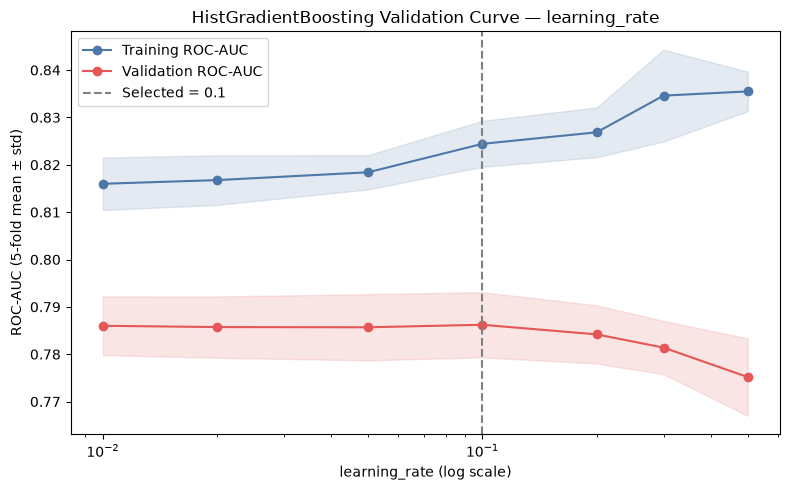

,Train ROC_AUC,Validation ROC_AUC,Gap
learning_rate,,,
0.01,0.8160,0.7860,0.0300
0.02,0.8168,0.7857,0.0310
0.05,0.8184,0.7857,0.0327
0.10,0.8244,0.7862,0.0382
0.20,0.8269,0.7842,0.0427
0.30,0.8346,0.7814,0.0532
0.50,0.8355,0.7752,0.0603


In [34]:
chosen_rate = hgb_best_params["model__learning_rate"]
hgb_curve = plot_validation_curve(
    hgb_tuned_pipeline, "model__learning_rate", sorted({0.01, 0.02, 0.05, 0.1, 0.2, 0.3, 0.5, chosen_rate}),
    chosen_rate, "HistGradientBoosting Validation Curve — learning_rate", "learning_rate (log scale)",
    "figures/09_hgb_validation_curve_learning_rate.png",
)
display(hgb_curve.round(4))
hgb_curve.to_csv("results/hgb_validation_curve.csv")

In [35]:
# Hand-over to Member 4
save_handover("hgb", "HistGradientBoosting", hgb_best_params, hgb_tuned_pipeline, hgb_tuned_cv_results)
print(f"Total search time: {(hgb_random_time + hgb_grid_time) / 60:.1f} minutes")

Tuned HistGradientBoosting parameters:
{
  "class_weight": null,
  "early_stopping": true,
  "l2_regularization": 10.0,
  "learning_rate": 0.1,
  "max_depth": null,
  "max_features": 0.5,
  "max_iter": 800,
  "max_leaf_nodes": 15,
  "min_samples_leaf": 20,
  "n_iter_no_change": 20
}


,Accuracy,ROC_AUC,Precision,Recall,F1
Model,,,,,
HistGradientBoosting (tuned),0.8213,0.7862,0.6758,0.3698,0.478


Total search time: 1.0 minutes


### HistGradientBoosting — findings

- **Best settings:** `learning_rate = 0.1`, `max_leaf_nodes = 15`, `min_samples_leaf = 20`, `l2_regularization = 10`, `max_features = 0.5`, no class weight; early stopping used only 88 of the allowed 800 trees.
- **Improvement:** validation ROC-AUC rose from 0.7830 to 0.7862 (+0.003). The default settings were already good; tuning mainly added regularisation.
- **Overfitting:** the train–validation gap halved, from 0.068 to 0.038.
- **Learning rate:** validation ROC-AUC is stable up to 0.1 and falls above 0.2 while the gap widens (figure 09).
- **Cost:** under 1 s per fold, roughly 18 times faster than the tuned Random Forest (16 s).

# Parts F and G — Ensemble, Evaluation and Comparison (Member 4)

1. Evaluate the three tuned models with **the same evaluation code**: same data, same 5 folds, same metrics.
2. Pick the two best models by **validation** ROC-AUC (training data only) for the ensemble.
3. Combine them with **soft voting** and with **stacking**, and keep the better one (soft voting if they are within 0.001, because it is simpler).
4. Test whether the ensemble is really better than the best single model.
5. Evaluate all four final models **once** on the reserved test set, at the usual 0.5 cut-off and at an F1-optimal cut-off chosen on training data.

In [36]:
from scipy import stats
from sklearn.ensemble import StackingClassifier, VotingClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, confusion_matrix,
    roc_auc_score, roc_curve,
)


def evaluate_cv(model):
    """5-fold scores, training scores, fit times and out-of-fold probabilities.
    Each customer's probability comes from the fold model that did not see them."""
    results = cross_validate(
        model, X_train_clean, y_train, cv=cv, scoring=scoring, return_train_score=True,
        return_estimator=True, return_indices=True, n_jobs=-1, error_score="raise",
    )
    oof = np.zeros(len(y_train))
    for fitted, val_idx in zip(results["estimator"], results["indices"]["test"]):
        oof[val_idx] = fitted.predict_proba(X_train_clean.iloc[val_idx])[:, 1]
    return results, oof


def cv_row(name, results):
    row = {"Model": name}
    for metric in scoring:
        row[metric] = results[f"test_{metric}"].mean()
        row[f"{metric} std"] = results[f"test_{metric}"].std(ddof=1)
    row["Train ROC_AUC"] = results["train_ROC_AUC"].mean()
    row["Gap (train - val)"] = row["Train ROC_AUC"] - row["ROC_AUC"]
    row["Fit time per fold (s)"] = results["fit_time"].mean()
    return row


def test_metrics(y_true, proba, threshold=0.5):
    predicted = (proba >= threshold).astype(int)
    return {
        "Accuracy": accuracy_score(y_true, predicted),
        "ROC_AUC": roc_auc_score(y_true, proba),
        "Precision": precision_score(y_true, predicted, pos_label=1, zero_division=0),
        "Recall": recall_score(y_true, predicted, pos_label=1, zero_division=0),
        "F1": f1_score(y_true, predicted, pos_label=1, zero_division=0),
    }


def best_f1_threshold(y_true, proba):
    """Cut-off that maximises F1 on out-of-fold (training) predictions."""
    thresholds = np.arange(0.05, 0.951, 0.01)
    scores = [f1_score(y_true, (proba >= t).astype(int), zero_division=0) for t in thresholds]
    return float(round(thresholds[int(np.argmax(scores))], 2))


# The three tuned models from Part E
tuned_models = {
    "Logistic Regression": clone(lr_tuned_pipeline),
    "Random Forest": clone(rf_tuned_pipeline),
    "HistGradientBoosting": clone(hgb_tuned_pipeline),
}

cv_results, oof_proba = {}, {}
for name, model in tuned_models.items():
    print(f"Evaluating {name}...")
    cv_results[name], oof_proba[name] = evaluate_cv(model)

base_table = pd.DataFrame([cv_row(n, r) for n, r in cv_results.items()]).set_index("Model")
base_table = base_table.sort_values("ROC_AUC", ascending=False)
print("Validation comparison of the three tuned models (same 5 folds)")
display(base_table.round(4))

# How similar are the models' predictions? Lower correlation = more diversity
oof_corr = pd.DataFrame(oof_proba).corr()
print("Correlation of out-of-fold default probabilities")
display(oof_corr.round(3))

Evaluating Logistic Regression...
Evaluating Random Forest...
Evaluating HistGradientBoosting...
Validation comparison of the three tuned models (same 5 folds)


,Accuracy,Accuracy std,ROC_AUC,ROC_AUC std,Precision,Precision std,Recall,Recall std,F1,F1 std,Train ROC_AUC,Gap (train - val),Fit time per fold (s)
Model,,,,,,,,,,,,,
HistGradientBoosting,0.8213,0.0024,0.7862,0.0069,0.6758,0.0121,0.3698,0.0058,0.4780,0.0065,0.8244,0.0382,0.7918
Random Forest,0.7717,0.0057,0.7859,0.0060,0.4874,0.0099,0.6163,0.0063,0.5443,0.0078,0.8888,0.1029,16.4600
Logistic Regression,0.8192,0.0034,0.7701,0.0062,0.6804,0.0177,0.3449,0.0144,0.4576,0.0138,0.7744,0.0043,0.1348


Correlation of out-of-fold default probabilities


,Logistic Regression,Random Forest,HistGradientBoosting
Logistic Regression,1.000,0.876,0.948
Random Forest,0.876,1.000,0.947
HistGradientBoosting,0.948,0.947,1.000


## Part F — Selecting the two ensemble members

In [37]:
ranking = base_table["ROC_AUC"]
selected = list(ranking.index[:2])
excluded = ranking.index[2]
print(f"Selected by validation ROC-AUC: {selected[0]} ({ranking.iloc[0]:.4f}) and {selected[1]} ({ranking.iloc[1]:.4f})")
print(f"Excluded: {excluded} ({ranking.iloc[2]:.4f}, {ranking.iloc[1] - ranking.iloc[2]:.4f} below the second model)")
print(f"Correlation between the two selected models: {oof_corr.loc[selected[0], selected[1]]:.3f}")

short = {"Logistic Regression": "lr", "Random Forest": "rf", "HistGradientBoosting": "hgb"}
members = [(short[name], clone(tuned_models[name])) for name in selected]

ensembles = {
    # Soft voting: average the two predicted probabilities
    "Soft Voting": VotingClassifier(estimators=members, voting="soft", n_jobs=1),
    # Stacking: a Logistic Regression learns how much to trust each model,
    # using out-of-fold predictions from an inner 5-fold split
    "Stacking": StackingClassifier(
        estimators=members,
        final_estimator=LogisticRegression(max_iter=2000),
        cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
        stack_method="predict_proba",
        n_jobs=1,
    ),
}

ensemble_results, ensemble_oof = {}, {}
for name, model in ensembles.items():
    print(f"Evaluating {name}...")
    start = time.perf_counter()
    ensemble_results[name], ensemble_oof[name] = evaluate_cv(model)
    print(f"  done in {(time.perf_counter() - start) / 60:.1f} minutes")

ensemble_table = pd.DataFrame([cv_row(n, r) for n, r in ensemble_results.items()]).set_index("Model")
display(ensemble_table.round(4))

TIE_MARGIN = 0.001
voting_auc, stacking_auc = ensemble_table.loc["Soft Voting", "ROC_AUC"], ensemble_table.loc["Stacking", "ROC_AUC"]
chosen_technique = "Stacking" if stacking_auc > voting_auc + TIE_MARGIN else "Soft Voting"
print(f"Chosen ensemble technique: {chosen_technique}")
ensemble_name = f"Ensemble ({chosen_technique}: {selected[0]} + {selected[1]})"

# Extra comparison: each model's F1-optimal cut-off, chosen on out-of-fold training predictions
thresholds = {name: best_f1_threshold(y_train, p) for name, p in oof_proba.items()}
thresholds[ensemble_name] = best_f1_threshold(y_train, ensemble_oof[chosen_technique])
print("F1-optimal thresholds (training data):", thresholds)

Selected by validation ROC-AUC: HistGradientBoosting (0.7862) and Random Forest (0.7859)
Excluded: Logistic Regression (0.7701, 0.0158 below the second model)
Correlation between the two selected models: 0.947
Evaluating Soft Voting...
  done in 0.4 minutes
Evaluating Stacking...
  done in 1.5 minutes


,Accuracy,Accuracy std,ROC_AUC,ROC_AUC std,Precision,Precision std,Recall,Recall std,F1,F1 std,Train ROC_AUC,Gap (train - val),Fit time per fold (s)
Model,,,,,,,,,,,,,
Soft Voting,0.8111,0.0049,0.7875,0.0065,0.5886,0.0134,0.4852,0.0106,0.5319,0.0117,0.8690,0.0815,17.1914
Stacking,0.8219,0.0031,0.7873,0.0064,0.6695,0.0148,0.3854,0.0052,0.4891,0.0068,0.8742,0.0869,85.3840


Chosen ensemble technique: Soft Voting
F1-optimal thresholds (training data): {'Logistic Regression': 0.27, 'Random Forest': 0.51, 'HistGradientBoosting': 0.28, 'Ensemble (Soft Voting: HistGradientBoosting + Random Forest)': 0.39}


## Part G — Does the ensemble beat the best single model on the five folds?

A paired t-test compares the fold-by-fold ROC-AUC. With only five overlapping folds it is optimistic and has little power, so the test-set bootstrap further below is a second check.

,Ensemble,HistGradientBoosting,Difference
Fold 1,0.7907,0.7906,0.0001
Fold 2,0.7878,0.7859,0.0019
Fold 3,0.7762,0.7744,0.0018
Fold 4,0.7921,0.7906,0.0015
Fold 5,0.7907,0.7895,0.0011


Mean difference: +0.0013 | paired t-test p = 0.019


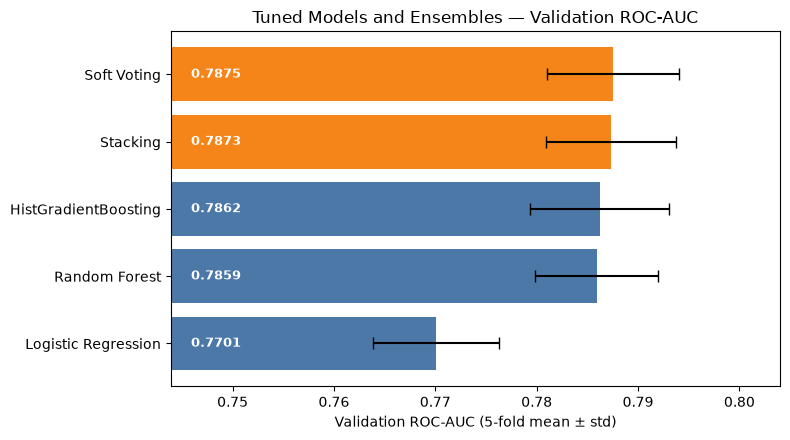

In [38]:
best_single = selected[0]
ens_folds = ensemble_results[chosen_technique]["test_ROC_AUC"]
best_folds = cv_results[best_single]["test_ROC_AUC"]
fold_diff = ens_folds - best_folds
p_value = stats.ttest_rel(ens_folds, best_folds).pvalue
display(pd.DataFrame({"Ensemble": ens_folds, best_single: best_folds, "Difference": fold_diff},
                     index=[f"Fold {i + 1}" for i in range(len(fold_diff))]).round(4))
print(f"Mean difference: {fold_diff.mean():+.4f} | paired t-test p = {p_value:.3f}")

all_cv = pd.concat([base_table, ensemble_table])
all_cv.to_csv("results/eval_cv_comparison.csv")
oof_corr.to_csv("results/eval_oof_correlation.csv")

# Figure: validation ROC-AUC of all five candidates
order = all_cv["ROC_AUC"].sort_values().index
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(order, all_cv.loc[order, "ROC_AUC"], xerr=all_cv.loc[order, "ROC_AUC std"], capsize=4,
        color=["#F58518" if n in ensembles else "#4C78A8" for n in order])
left = max(0.5, (all_cv["ROC_AUC"] - all_cv["ROC_AUC std"]).min() - 0.02)
ax.set_xlim(left, min(1.0, (all_cv["ROC_AUC"] + all_cv["ROC_AUC std"]).max() + 0.01))
for i, n in enumerate(order):
    ax.text(left + 0.002, i, f"{all_cv.loc[n, 'ROC_AUC']:.4f}", va="center", fontsize=9,
            color="white", fontweight="bold")
ax.set_xlabel("Validation ROC-AUC (5-fold mean ± std)")
ax.set_title("Tuned Models and Ensembles — Validation ROC-AUC")
fig.tight_layout()
fig.savefig("figures/10_cv_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

## Part G — Final evaluation on the reserved test set (used once)

Each final model is fitted on the full training set and evaluated once on `X_test_clean`.

In [39]:
final_models = {name: clone(model) for name, model in tuned_models.items()}
final_models[ensemble_name] = clone(ensembles[chosen_technique])

test_rows, tuned_rows, test_proba, confusion = [], [], {}, {}
for name, model in final_models.items():
    start = time.perf_counter()
    model.fit(X_train_clean, y_train)
    fit_time = time.perf_counter() - start

    start = time.perf_counter()
    proba = model.predict_proba(X_test_clean)[:, 1]
    predict_time = time.perf_counter() - start

    test_proba[name] = proba
    confusion[name] = confusion_matrix(y_test, (proba >= 0.5).astype(int))
    tuned_rows.append({"Model": name, "Threshold": thresholds[name],
                       **test_metrics(y_test, proba, thresholds[name])})
    row = {"Model": name, **test_metrics(y_test, proba)}
    row["Train ROC_AUC"] = roc_auc_score(y_train, model.predict_proba(X_train_clean)[:, 1])
    row["Gap (train - test)"] = row["Train ROC_AUC"] - row["ROC_AUC"]
    row["Fit time (s)"] = fit_time
    row["Predict time per 1,000 customers (ms)"] = predict_time / len(X_test_clean) * 1e6
    test_rows.append(row)

test_table = pd.DataFrame(test_rows).set_index("Model")
print("Test set — threshold 0.5")
display(test_table.round(4))
test_table.to_csv("results/eval_test_results.csv")

tuned_threshold_table = pd.DataFrame(tuned_rows).set_index("Model")
print("Test set — F1-optimal threshold chosen on training data")
display(tuned_threshold_table.round(4))
tuned_threshold_table.to_csv("results/eval_test_results_tuned_threshold.csv")

confusion_table = pd.DataFrame(
    [{"Model": n, **dict(zip(["TN", "FP", "FN", "TP"], m.ravel()))} for n, m in confusion.items()]
).set_index("Model")
print("Confusion matrices (threshold 0.5)")
display(confusion_table)
confusion_table.to_csv("results/eval_confusion_matrices.csv")

Test set — threshold 0.5


,Accuracy,ROC_AUC,Precision,Recall,F1,Train ROC_AUC,Gap (train - test),Fit time (s),"Predict time per 1,000 customers (ms)"
Model,,,,,,,,,
Logistic Regression,0.8160,0.7601,0.6614,0.3444,0.4529,0.7741,0.0140,0.1082,1.8070
Random Forest,0.7705,0.7764,0.4850,0.6081,0.5396,0.8895,0.1132,18.5898,46.0306
HistGradientBoosting,0.8187,0.7797,0.6621,0.3677,0.4729,0.8192,0.0395,0.3634,2.8344
Ensemble (Soft Voting: HistGradientBoosting + Random Forest),0.8107,0.7790,0.5882,0.4800,0.5286,0.8679,0.0889,18.7635,50.6626


Test set — F1-optimal threshold chosen on training data


,Threshold,Accuracy,ROC_AUC,Precision,Recall,F1
Model,,,,,,
Logistic Regression,0.27,0.7950,0.7601,0.5390,0.5049,0.5214
Random Forest,0.51,0.7780,0.7764,0.4984,0.6006,0.5448
HistGradientBoosting,0.28,0.7875,0.7797,0.5182,0.5592,0.5379
Ensemble (Soft Voting: HistGradientBoosting + Random Forest),0.39,0.7837,0.7790,0.5094,0.5938,0.5484


Confusion matrices (threshold 0.5)


,TN,FP,FN,TP
Model,,,,
Logistic Regression,4439,234,870,457
Random Forest,3816,857,520,807
HistGradientBoosting,4424,249,839,488
Ensemble (Soft Voting: HistGradientBoosting + Random Forest),4227,446,690,637


### Is the ensemble significantly better on the test set?

1,000 bootstrap resamples of the test customers give a 95% interval for the ROC-AUC difference between the ensemble and each of its members. An interval above zero means a clear improvement.

In [40]:
rng = np.random.default_rng(42)
y_test_array = y_test.to_numpy()
samples = []
while len(samples) < 1000:
    idx = rng.integers(0, len(y_test_array), len(y_test_array))
    if y_test_array[idx].min() != y_test_array[idx].max():   # a resample needs both classes
        samples.append(idx)

significance_rows = []
for member in selected:
    ens_p, mem_p = test_proba[ensemble_name], test_proba[member]
    diffs = np.array([roc_auc_score(y_test_array[i], ens_p[i]) - roc_auc_score(y_test_array[i], mem_p[i])
                      for i in samples])
    ci_low, ci_high = np.percentile(diffs, [2.5, 97.5])
    member_folds = cv_results[member]["test_ROC_AUC"]
    significance_rows.append({
        "Comparison": f"Ensemble - {member}",
        "CV mean difference": (ens_folds - member_folds).mean(),
        "CV paired t-test p": stats.ttest_rel(ens_folds, member_folds).pvalue,
        "Test difference": test_table.loc[ensemble_name, "ROC_AUC"] - test_table.loc[member, "ROC_AUC"],
        "Bootstrap 2.5%": ci_low,
        "Bootstrap 97.5%": ci_high,
        "Ensemble better in % of resamples": np.mean(diffs > 0) * 100,
        "Clear improvement": bool(ci_low > 0),
    })
significance = pd.DataFrame(significance_rows).set_index("Comparison")
display(significance.round(4))
significance.to_csv("results/eval_ensemble_significance.csv")

,CV mean difference,CV paired t-test p,Test difference,Bootstrap 2.5%,Bootstrap 97.5%,Ensemble better in % of resamples,Clear improvement
Comparison,,,,,,,
Ensemble - HistGradientBoosting,0.0013,0.0186,-0.0007,-0.0033,0.0019,28.2,False
Ensemble - Random Forest,0.0016,0.0037,0.0026,0.0010,0.0041,99.9,True


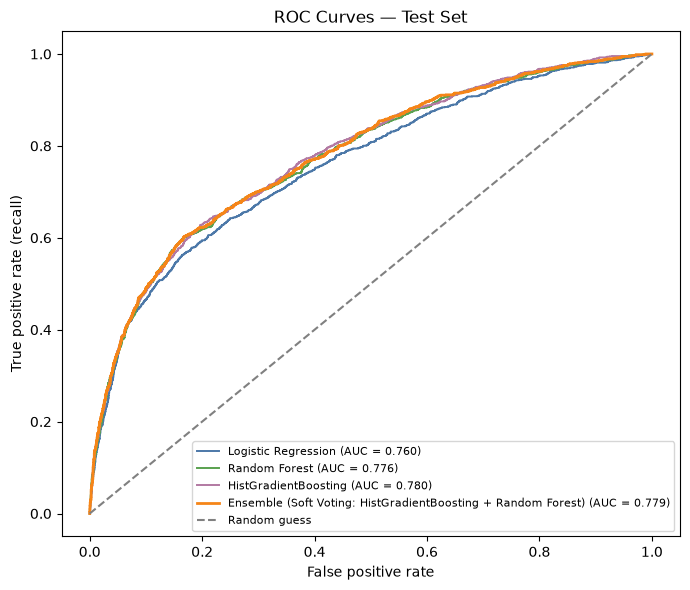

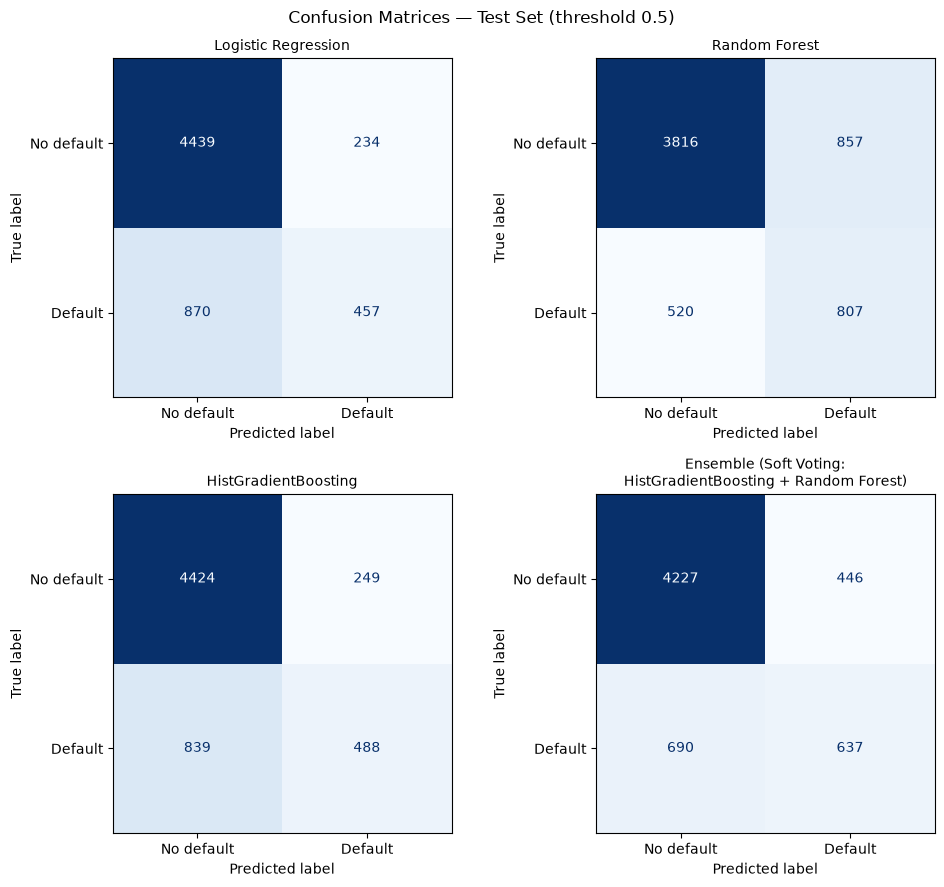

In [41]:
# Figure: ROC curves on the test set
fig, ax = plt.subplots(figsize=(7, 6))
for color, (name, proba) in zip(["#4C78A8", "#59A14F", "#B279A2", "#F58518"], test_proba.items()):
    fpr, tpr, _ = roc_curve(y_test, proba)
    ax.plot(fpr, tpr, color=color, linewidth=2 if name == ensemble_name else 1.4,
            label=f"{name} (AUC = {roc_auc_score(y_test, proba):.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Random guess")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate (recall)")
ax.set_title("ROC Curves — Test Set")
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout()
fig.savefig("figures/11_roc_curves_test.png", dpi=300, bbox_inches="tight")
plt.show()

# Figure: confusion matrices on the test set
fig, axes = plt.subplots(2, 2, figsize=(10, 9))
for ax, (name, matrix) in zip(axes.ravel(), confusion.items()):
    ConfusionMatrixDisplay(matrix, display_labels=["No default", "Default"]).plot(
        ax=ax, colorbar=False, values_format="d", cmap="Blues")
    ax.set_title(name if len(name) < 40 else name.replace(": ", ":\n"), fontsize=10)
fig.suptitle("Confusion Matrices — Test Set (threshold 0.5)")
fig.tight_layout()
fig.savefig("figures/12_confusion_matrices_test.png", dpi=300, bbox_inches="tight")
plt.show()

## Findings and recommendation

**Ensemble (Part F).** HistGradientBoosting (validation ROC-AUC 0.7862) and Random Forest (0.7859) were selected; Logistic Regression (0.7701) was excluded because it was 0.016 lower. Soft voting (0.7875) and stacking (0.7873) scored the same, so soft voting was kept: it is simpler, has no extra model to overfit and trained about five times faster (17 s vs 85 s per fold).

**Test set (Part G, used once).**

| Model | ROC-AUC | Accuracy | Precision | Recall | F1 | Train − test gap | Training time |
|---|---|---|---|---|---|---|---|
| HistGradientBoosting | **0.780** | 0.819 | 0.662 | 0.368 | 0.473 | 0.040 | 0.4 s |
| Ensemble (soft voting) | 0.779 | 0.811 | 0.588 | 0.480 | 0.529 | 0.089 | 18.8 s |
| Random Forest | 0.776 | 0.771 | 0.485 | 0.608 | 0.540 | 0.113 | 18.6 s |
| Logistic Regression | 0.760 | 0.816 | 0.661 | 0.344 | 0.453 | 0.014 | 0.1 s |

**Did the ensemble improve performance?** Not significantly over HistGradientBoosting: the test difference is −0.0007 and the 95% bootstrap interval (−0.003 to +0.002) includes zero. On the five folds it led by only 0.001 (p = 0.019), too small to matter in practice. It does beat Random Forest (+0.0026, interval +0.001 to +0.004). The two members' predictions are 0.95 correlated, so they make similar mistakes and averaging adds little.

**Threshold.** With F1-optimal cut-offs chosen on training data, all four models reach an F1 of 0.52–0.55; the ensemble is highest (0.548) but only 0.01 above HistGradientBoosting (0.538 at a 0.28 cut-off, recall 0.56).

**Recommendation.** HistGradientBoosting with a 0.28 cut-off: the best ROC-AUC, a small overfitting gap, training in under a second and the simplest model of the top group. The ensemble is about 50 times slower to train and harder to explain for no significant gain. If every decision must be explained to customers, Logistic Regression is a reasonable fallback at a cost of 0.02 ROC-AUC.

**Limitations.** The data come from one Taiwanese bank in 2005; the real costs of a missed defaulter and a false alarm were not available, so the cut-off maximises F1 rather than profit; HistGradientBoosting needs tools such as SHAP to explain individual predictions.